
# Task 01 — Multi-Class Benchmark Classification

**Internship:** Datheon — Machine Learning and Data Science  
**Dataset:** Iris Flower Dataset  
**Author:** Dilara Liyanage  
**Tools:** Python, Pandas, NumPy, Scikit-Learn, Matplotlib, Seaborn

## 1. Introduction

This project focuses on developing a multi-class classification pipeline using the Iris flower dataset. The main objective is to classify three Iris flower species based on four numerical measurements: sepal length, sepal width, petal length, and petal width.

Two supervised machine learning algorithms, Logistic Regression and Decision Tree, will be implemented and compared.

The project follows a standard machine learning workflow, including data exploration, preprocessing, model training, evaluation, and visualization.

### Objectives

1. Explore the dataset and identify patterns in the flower measurements.
2. Prepare the dataset for supervised classification.
3. Train Logistic Regression and Decision Tree classifiers.
4. Evaluate model performance using accuracy, precision, recall, and F1-score.
5. Generate confusion matrices and decision boundary visualizations.
6. Compare the models and discuss their performance and limitations.

### Dataset

The Iris dataset contains 150 observations belonging to three species: setosa, versicolor, and virginica.

Each observation includes four numerical flower measurements and one categorical target label.

**Source:** https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv

In [1]:

# ============================================================
# Task 01: Iris Multi-Class Classification
# Section 2: Import Required Libraries
# ============================================================

# Data manipulation and numerical operations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility
RANDOM_STATE = 42

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.



## 3. Dataset Loading

The Iris dataset is loaded from the local `data` directory using Pandas.

The dataset will be kept in its original form during the initial inspection. Any preprocessing required for model training will be performed in later sections.

The first five observations are displayed to understand the dataset structure and available attributes.

In [2]:

# ============================================================
# Section 3: Load the Iris Dataset
# ============================================================

from pathlib import Path

# Resolve the dataset path relative to the repository root
# or the Task 01 notebook directory.
possible_paths = [
    Path("Task_01_Multi_Class_Classification/data/iris.csv"),
    Path("../data/iris.csv"),
    Path("data/iris.csv"),
]

dataset_path = next(
    (path for path in possible_paths if path.is_file()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "iris.csv was not found. Check the Task 01 data folder."
    )

# Load the original dataset
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")
print("\nFirst five records:")

display(df.head())

Dataset loaded successfully.
Dataset shape: (150, 5)

First five records:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is carried out to understand the characteristics of the Iris dataset before developing the classification models.

The initial inspection focuses on identifying the dataset structure, feature types, missing values, duplicate observations, and the distribution of flower species.

These checks help determine whether additional data cleaning or preprocessing is required before model training.

### 4.1 Initial Dataset Inspection

The dataset will be examined using Pandas to identify its dimensions, column names, data types, missing values, and duplicate records.

The distribution of the target variable will also be checked to determine whether the dataset is balanced across the three Iris species.

In [3]:

# ============================================================
# Section 4.1: Initial Dataset Inspection
# ============================================================

# 1. Dataset dimensions
print("1. DATASET DIMENSIONS")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

# 2. Column names
print("\n2. COLUMN NAMES")
print(df.columns.tolist())

# 3. Dataset information and data types
print("\n3. DATASET INFORMATION")
df.info()

# 4. Missing values
print("\n4. MISSING VALUES")
print(df.isnull().sum())
print(f"Total missing values: {df.isnull().sum().sum()}")

# 5. Duplicate observations
print("\n5. DUPLICATE RECORDS")
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate records: {duplicate_count}")

# 6. Target class distribution
print("\n6. TARGET CLASS DISTRIBUTION")
print(df["species"].value_counts())

# 7. Unique target classes
print("\n7. UNIQUE SPECIES")
print(df["species"].unique())

1. DATASET DIMENSIONS
Number of rows: 150
Number of columns: 5

2. COLUMN NAMES
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

3. DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB

4. MISSING VALUES
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Total missing values: 0

5. DUPLICATE RECORDS
Number of duplicate records: 1

6. TARGET CLASS DISTRIBUTION
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

7. UNIQUE SPECIES
<StringArray>
['setosa', 'versicolor', 'virgini


### 4.1.1 Initial Inspection Summary

The Iris dataset contains 150 observations and five columns. Four columns represent numerical flower measurements, while the `species` column is the categorical target variable.

The initial inspection identified no missing values. Therefore, missing-value imputation is not required for this dataset.

The three Iris species are equally represented, with 50 observations per class. This balanced distribution provides a suitable starting point for comparing multi-class classification algorithms.

One duplicate observation was identified. The original dataset will be preserved, and duplicate handling will be considered during preprocessing to prevent potential overlap between training and testing data.

Based on these initial findings, the dataset is suitable for proceeding with descriptive statistical analysis and visualization.


### 4.2 Descriptive Statistical Analysis

Descriptive statistical analysis is used to summarize the numerical characteristics of the Iris dataset.

The analysis focuses on the four flower measurements: sepal length, sepal width, petal length, and petal width.

Pandas is used to calculate the count, mean, standard deviation, minimum, maximum, and quartile values for each feature.

These statistics provide an initial understanding of the typical measurements and the variation present in the dataset. They also help identify differences in feature scales that may need to be considered during preprocessing.

In [4]:

# ============================================================
# Section 4.2: Descriptive Statistical Analysis
# ============================================================

# Select the four numerical flower measurements
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Generate descriptive statistics
descriptive_stats = df[feature_columns].describe()

# Display the statistical summary
print("DESCRIPTIVE STATISTICS OF IRIS FEATURES")
display(descriptive_stats.round(2))

DESCRIPTIVE STATISTICS OF IRIS FEATURES


,sepal_length,sepal_width,petal_length,petal_width
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [5]:

# ============================================================
# Section 4.2: Mean Feature Values by Species
# ============================================================

# Calculate average measurements for each Iris species
species_means = df.groupby("species")[feature_columns].mean()

print("MEAN FEATURE VALUES BY IRIS SPECIES")
display(species_means.round(2))


MEAN FEATURE VALUES BY IRIS SPECIES


,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03



### 4.2.1 Statistical Analysis Summary

The descriptive statistical analysis shows that the four numerical features have different ranges and levels of variation.

Petal length has the highest standard deviation among the four measurements, while sepal width has the lowest. This indicates that petal length varies more across the complete dataset in absolute terms.

The species-wise mean comparison shows noticeable differences in petal measurements. Setosa has the smallest average petal length and width, followed by versicolor and virginica.

These findings suggest that petal measurements could be useful for distinguishing between Iris species. However, further visual analysis is required to examine how much the feature distributions overlap.

The differences in feature scales also support considering standardization when training Logistic Regression.

Overall, the statistical results provide a useful foundation for the next stage of exploratory data analysis.


### 4.3 Iris Species Distribution

The distribution of the target variable is examined to determine whether the dataset contains an equal number of observations for each Iris species.

A count plot is used to visualize the number of samples belonging to setosa, versicolor, and virginica.

Class distribution is important in supervised classification because imbalanced datasets may cause a model to favor classes with more observations.

The results will help determine whether specific class imbalance handling techniques are necessary before model training.

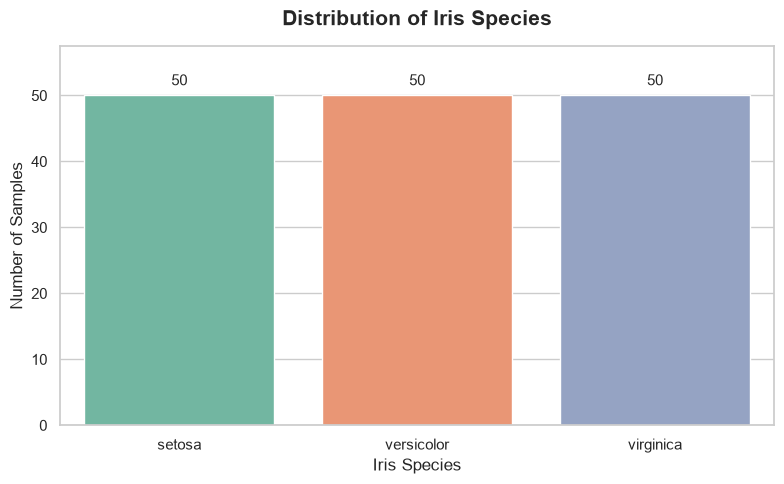

Visualization saved to: ..\outputs\iris_class_distribution.png

Class Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [6]:

# ============================================================
# Section 4.3: Iris Species Distribution Visualization
# ============================================================

# Define a consistent order for the species
species_order = ["setosa", "versicolor", "virginica"]

# Calculate the number of samples in each class
class_counts = (
    df["species"]
    .value_counts()
    .reindex(species_order)
)

# Create the visualization
fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    order=species_order,
    hue="species",
    palette="Set2",
    legend=False,
    ax=ax
)

# Add count labels above the bars
for bar in ax.patches:
    height = bar.get_height()

    ax.annotate(
        f"{int(height)}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Customize the plot
ax.set_title(
    "Distribution of Iris Species",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Iris Species", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.set_ylim(0, class_counts.max() * 1.15)

plt.tight_layout()

# Locate the Task 01 outputs directory
output_candidates = [
    Path("Task_01_Multi_Class_Classification/outputs"),
    Path("../outputs"),
    Path("outputs")
]

output_dir = next(
    (path for path in output_candidates if path.is_dir()),
    None
)

if output_dir is None:
    raise FileNotFoundError(
        "Task 01 outputs directory was not found."
    )

# Save the figure
plot_path = output_dir / "iris_class_distribution.png"

fig.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

print(f"Visualization saved to: {plot_path}")
print("\nClass Distribution:")
print(class_counts)


### 4.3.1 Class Distribution Analysis

The class distribution visualization shows that the Iris dataset contains an equal number of observations for all three species.

Each species, setosa, versicolor, and virginica, contains 50 samples, representing approximately 33.33% of the dataset.

This confirms that the target variable is balanced, so class imbalance handling techniques such as oversampling or undersampling are not required for the initial classification experiments.

However, a balanced class distribution does not guarantee equal classification performance across all species. Some classes may still be more difficult to distinguish because their feature measurements overlap.

A stratified train-test split will therefore be used during preprocessing to preserve the class proportions in the training and testing subsets.

The next stage of EDA will examine the distributions of individual flower measurements and their relationships across the three species.


### 4.4 Feature Distribution Analysis

Feature distribution analysis is performed to examine how the four numerical flower measurements vary across the three Iris species.

Histograms with Kernel Density Estimation (KDE) curves are used to visualize the distributions of sepal length, sepal width, petal length, and petal width.

The histograms show the frequency of observations within different measurement ranges, while KDE curves provide smoothed estimates of the feature distributions.

By comparing the distributions across species, it is possible to identify features that may provide better separation between classes.

The analysis also helps identify overlapping measurements that could make classification more challenging.

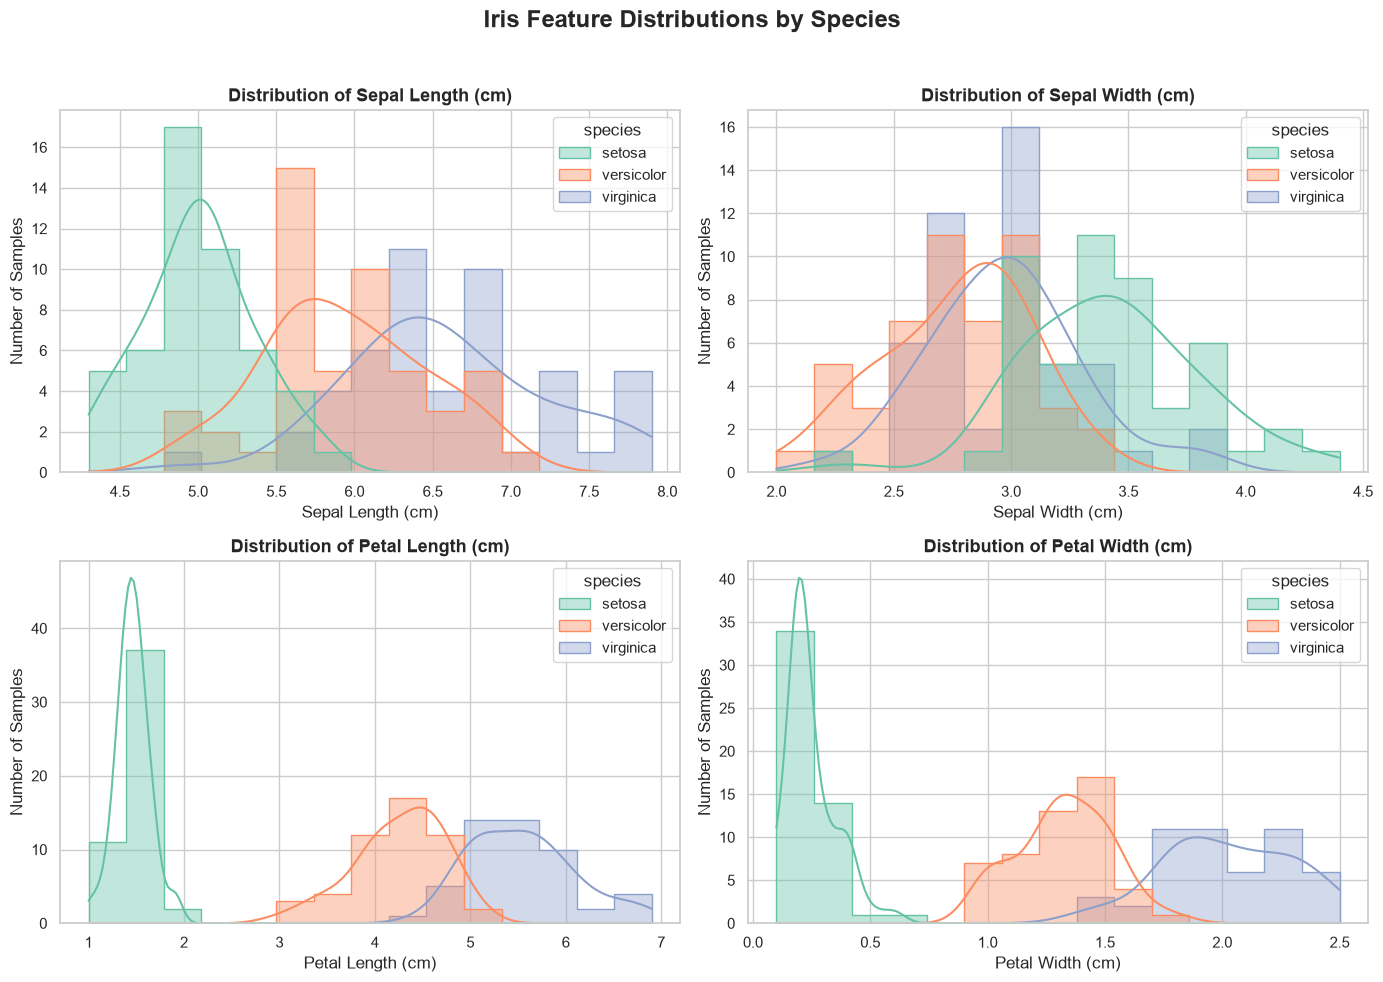

Feature distribution plot saved to: ..\outputs\iris_feature_distributions.png


In [7]:

# ============================================================
# Section 4.4: Feature Distribution Analysis
# ============================================================

# Feature names and their display labels
feature_labels = {
    "sepal_length": "Sepal Length (cm)",
    "sepal_width": "Sepal Width (cm)",
    "petal_length": "Petal Length (cm)",
    "petal_width": "Petal Width (cm)"
}

# Consistent species ordering and colors
species_order = ["setosa", "versicolor", "virginica"]
species_palette = {
    "setosa": "#66c2a5",
    "versicolor": "#fc8d62",
    "virginica": "#8da0cb"
}

# Create a 2x2 grid of histograms
fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 10)
)

# Generate one histogram for each feature
for ax, (feature, label) in zip(
    axes.flatten(),
    feature_labels.items()
):
    sns.histplot(
        data=df,
        x=feature,
        hue="species",
        hue_order=species_order,
        palette=species_palette,
        bins=15,
        kde=True,
        stat="count",
        common_norm=False,
        alpha=0.4,
        element="step",
        ax=ax
    )

    ax.set_title(
        f"Distribution of {label}",
        fontsize=13,
        fontweight="bold"
    )
    ax.set_xlabel(label)
    ax.set_ylabel("Number of Samples")

# Add the main title
fig.suptitle(
    "Iris Feature Distributions by Species",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout(rect=(0, 0, 1, 0.96))

# Reuse the output directory identified in Step 4.2.3
plot_path = output_dir / "iris_feature_distributions.png"

# Save the visualization before displaying
fig.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Feature distribution plot saved to: {plot_path}")



### 4.4.1 Feature Distribution Analysis — Observations

The feature distribution plots show noticeable differences between the four flower measurements.

**Sepal Length:** Setosa generally has shorter sepals, while virginica tends to have longer sepals. However, considerable overlap is visible between versicolor and virginica.

**Sepal Width:** The distributions overlap across the three species. Setosa generally has a higher sepal width, but this feature alone may not provide clear separation between all classes.

**Petal Length:** Setosa has substantially shorter petals compared with the other two species. Versicolor and virginica also show differences, although some overlap remains.

**Petal Width:** Setosa has the smallest petal widths, followed by versicolor and virginica. This feature shows noticeable differences between the species, with some overlap between versicolor and virginica.

Overall, petal length and petal width appear more useful for distinguishing the three Iris species than the sepal measurements.

However, these observations are based on visual exploration. The actual predictive usefulness of each feature will be examined through model training and evaluation.


### 4.5 Pair Plot Analysis

A pair plot is used to explore relationships between the four numerical features in the Iris dataset.

The visualization compares sepal length, sepal width, petal length, and petal width using scatter plots for each pair of features. The diagonal plots show the distribution of each individual measurement.

The three Iris species are represented using different colors to examine how their observations are grouped in the feature space.

This analysis helps identify feature combinations that may be useful for distinguishing flower species and highlights areas where class distributions overlap.

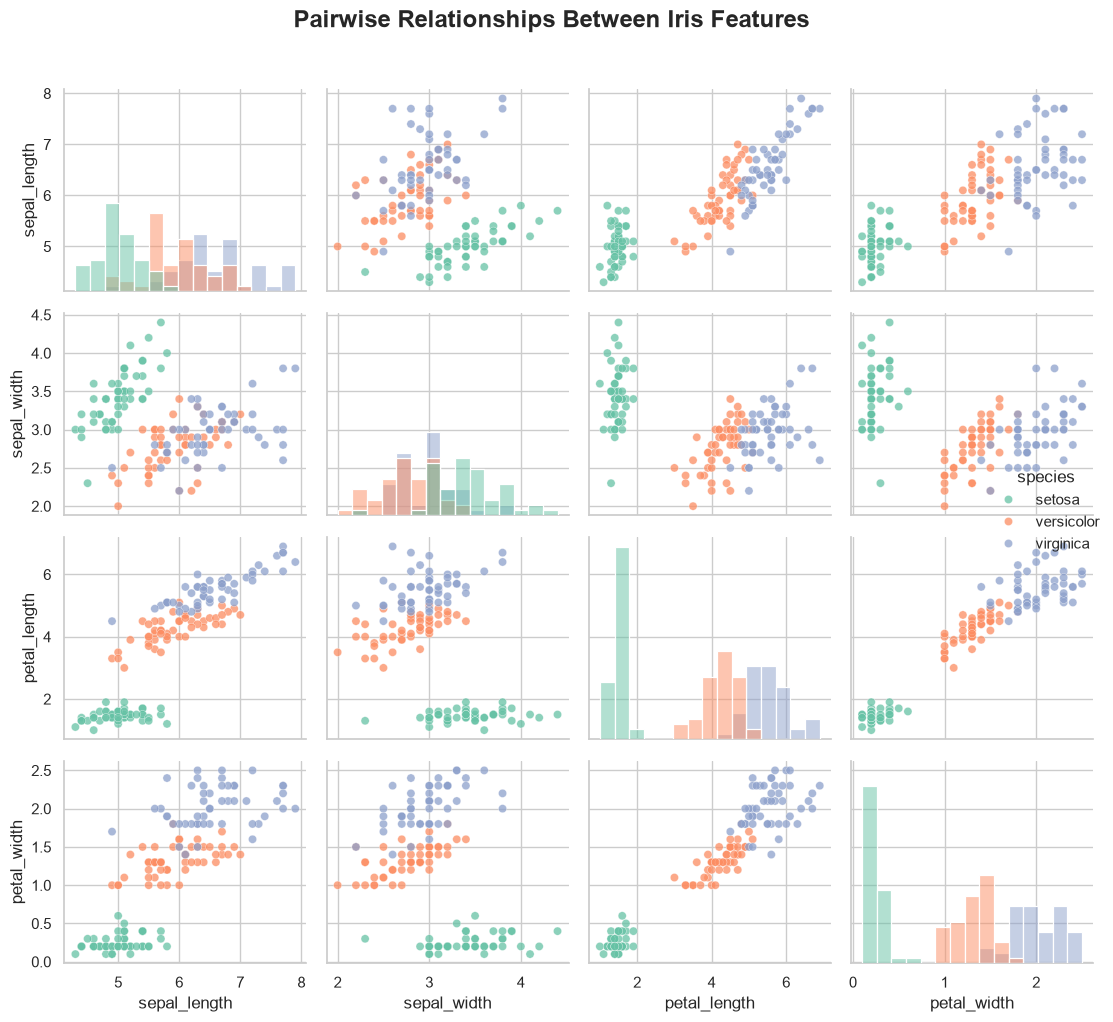

Pair plot saved to: ..\outputs\iris_pairplot.png


In [8]:

# ============================================================
# Section 4.5: Iris Pair Plot Analysis
# ============================================================

# Use the original dataset and four numerical features
pairplot_data = df[feature_columns + ["species"]].copy()

# Create the pair plot
pair_grid = sns.pairplot(
    data=pairplot_data,
    vars=feature_columns,
    hue="species",
    hue_order=species_order,
    palette=species_palette,
    diag_kind="hist",
    corner=False,
    height=2.5,
    plot_kws={
        "alpha": 0.75,
        "s": 35,
        "edgecolor": "white",
        "linewidth": 0.3
    },
    diag_kws={
        "alpha": 0.5,
        "bins": 15
    }
)

# Add the main title
pair_grid.figure.suptitle(
    "Pairwise Relationships Between Iris Features",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

# Improve figure spacing
pair_grid.figure.tight_layout()

# Save the visualization
pairplot_path = output_dir / "iris_pairplot.png"

pair_grid.figure.savefig(
    pairplot_path,
    dpi=300,
    bbox_inches="tight"
)

# Display the figure
plt.show()

print(f"Pair plot saved to: {pairplot_path}")



### 4.5.1 Pair Plot Analysis — Observations

The pair plot provides a visual comparison of the relationships between the four numerical flower measurements.

The scatter plots show that setosa forms a relatively distinct group, particularly when petal length and petal width are considered together.

Versicolor and virginica show some overlapping observations, suggesting that distinguishing these two species may be more challenging than identifying setosa.

The petal length and petal width combination provides clearer visual separation between the species than the sepal length and sepal width combination.

The pair plot also indicates a positive relationship between petal length and petal width. Flowers with longer petals generally tend to have wider petals.

These findings suggest that petal measurements may contribute strongly to classification performance. However, visual separation does not guarantee perfect predictions, and the usefulness of each feature will be assessed through model evaluation.

All four numerical features will be retained for the main classification experiments. A two-feature combination may also be used later to visualize model decision boundaries.

The next stage of exploratory data analysis will examine the strength and direction of numerical feature relationships using a correlation matrix.


### 4.6 Feature Correlation Analysis

Correlation analysis is performed to examine the strength and direction of linear relationships between the numerical features in the Iris dataset.

Pearson's correlation coefficient is used to calculate the correlation between sepal length, sepal width, petal length, and petal width.

The resulting correlation matrix is visualized using a Seaborn heatmap.

This analysis helps identify strongly related features and possible multicollinearity. However, correlation between input features does not directly measure their importance for predicting the target species.


PEARSON CORRELATION MATRIX


,sepal_length,sepal_width,petal_length,petal_width
sepal_length,1.000,-0.118,0.872,0.818
sepal_width,-0.118,1.000,-0.428,-0.366
petal_length,0.872,-0.428,1.000,0.963
petal_width,0.818,-0.366,0.963,1.000


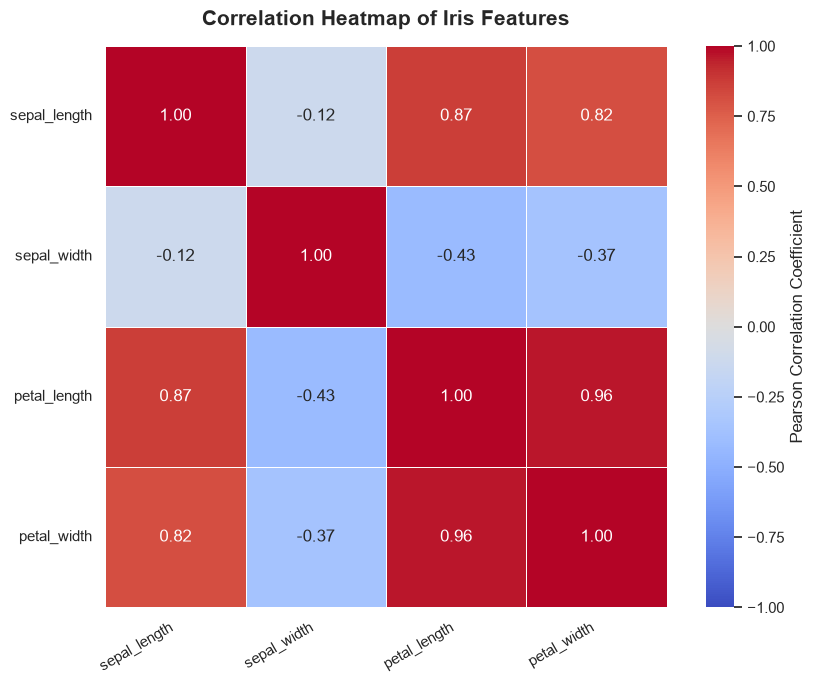

Correlation heatmap saved to: ..\outputs\iris_correlation_heatmap.png


In [9]:

# ============================================================
# Section 4.6: Feature Correlation Analysis
# ============================================================

# Calculate Pearson correlations for numerical features
correlation_matrix = df[feature_columns].corr(
    method="pearson"
)

print("PEARSON CORRELATION MATRIX")
display(correlation_matrix.round(3))

# Create the heatmap
fig, ax = plt.subplots(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={
        "label": "Pearson Correlation Coefficient"
    },
    ax=ax
)

# Customize the chart
ax.set_title(
    "Correlation Heatmap of Iris Features",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=30,
    ha="right"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

plt.tight_layout()

# Save to the existing Task 01 outputs folder
correlation_plot_path = (
    output_dir / "iris_correlation_heatmap.png"
)

fig.savefig(
    correlation_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Correlation heatmap saved to: "
    f"{correlation_plot_path}"
)



### 4.6.1 Correlation Analysis — Observations

The correlation heatmap shows several relationships between the numerical features in the Iris dataset.

The strongest positive correlation is observed between petal length and petal width, with a Pearson correlation coefficient of approximately 0.96. This indicates that flowers with longer petals generally tend to have wider petals.

Sepal length also has strong positive correlations with petal length (approximately 0.87) and petal width (approximately 0.82).

In comparison, sepal width has a weak negative correlation with sepal length and moderate negative correlations with the petal measurements.

These results indicate that some input features contain related information, particularly the petal measurements.

This may introduce multicollinearity in linear models. However, correlated features are not necessarily redundant for classification, and removing them without validation could reduce useful information.

Therefore, all four numerical features will be retained for the initial Logistic Regression and Decision Tree experiments.

The dataset will be split into training and testing subsets before fitting the feature scaler. Model performance will then be evaluated using unseen test observations.

Overall, the correlation analysis supports the findings from the previous pair plots and provides a better understanding of the relationships between the input features.


## 5. Data Preprocessing

Data preprocessing is performed to prepare the Iris dataset for supervised classification using Logistic Regression and Decision Tree algorithms.

The preprocessing stage includes:

1. Handling duplicate observations.
2. Separating numerical features and the target variable.
3. Dividing the dataset into training and testing subsets.
4. Standardizing numerical features where required.
5. Verifying that the preprocessing steps do not introduce data leakage.

The original dataset will be preserved, and a separate DataFrame will be used for model development.

### 5.1 Duplicate Observation Handling

The initial data inspection identified one completely duplicated observation in the Iris dataset.

Exact duplicate records will be removed before the train-test split to prevent identical observations from appearing in both the training and testing subsets.

A separate copy of the dataset will be created for modelling so that the original data remains unchanged.

After duplicate removal, the number of observations and class distribution will be verified.

In [10]:

# ============================================================
# Section 5.1: Duplicate Observation Handling
# ============================================================

# Preserve the original dataset for reference
df_original = df.copy()

print("ORIGINAL DATASET")
print(f"Total observations: {len(df_original)}")

# Identify exact duplicate records
duplicate_mask = df_original.duplicated(keep="first")
duplicate_count = duplicate_mask.sum()

print(f"Duplicate observations: {duplicate_count}")

# Display duplicate records, if any
if duplicate_count > 0:
    print("\nDuplicate observations identified:")
    display(df_original.loc[duplicate_mask])

# Create a separate dataset for model development
# and remove exact duplicates
df_model = (
    df_original
    .drop_duplicates(keep="first")
    .reset_index(drop=True)
    .copy()
)

print("\nDATASET AFTER DUPLICATE REMOVAL")
print(f"Original observations: {len(df_original)}")
print(f"Removed duplicates: {duplicate_count}")
print(f"Remaining observations: {len(df_model)}")

# Verify there are no remaining exact duplicates
remaining_duplicates = df_model.duplicated().sum()

print(
    f"Remaining duplicate observations: "
    f"{remaining_duplicates}"
)

# Verify target class distribution
print("\nCLASS DISTRIBUTION AFTER CLEANING")
display(
    df_model["species"]
    .value_counts()
    .sort_index()
)

# Confirm the cleaning operation was successful
assert remaining_duplicates == 0, (
    "Duplicate observations remain in the modelling dataset."
)

assert len(df_original) == len(df_model) + duplicate_count, (
    "Dataset row count does not match the cleaning results."
)

print("\nDuplicate handling completed successfully.")


ORIGINAL DATASET
Total observations: 150
Duplicate observations: 1

Duplicate observations identified:


,sepal_length,sepal_width,petal_length,petal_width,species
142,5.8,2.7,5.1,1.9,virginica



DATASET AFTER DUPLICATE REMOVAL
Original observations: 150
Removed duplicates: 1
Remaining observations: 149
Remaining duplicate observations: 0

CLASS DISTRIBUTION AFTER CLEANING


species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: int64


Duplicate handling completed successfully.



### 5.1.1 Duplicate Handling — Observations

The original Iris dataset contained 150 observations, including one exact duplicate record.

The duplicated observation was removed from a separate modelling DataFrame, reducing the dataset to 149 unique observations. The original dataset was preserved without modification.

Duplicate removal was completed before the train-test split to reduce the risk of identical records appearing in both training and testing data.

After cleaning, the dataset contained no remaining exact duplicates. The class distribution remained approximately balanced, with only one observation removed.

The cleaned dataset will be used for the remaining preprocessing and model development stages.

This approach supports a more reliable evaluation of the Logistic Regression and Decision Tree classifiers.


### 5.2 Feature and Target Separation

The cleaned Iris dataset is separated into input features (X) and target labels (y).

The input features consist of four numerical flower measurements: sepal length, sepal width, petal length, and petal width.

The target variable is `species`, which represents one of the three Iris flower categories.

Separating the features and target is necessary for supervised learning because the classification models will learn to predict the species based on the flower measurements.

The target labels will be retained as strings because Scikit-Learn supports categorical class labels directly. This also makes the model predictions and classification reports easier to interpret.

In [11]:

# ============================================================
# Section 5.2: Feature and Target Separation
# ============================================================

# Define the input feature columns
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]

# Define the target column
target_column = "species"

# Separate input features and target labels
X = df_model[feature_columns].copy()
y = df_model[target_column].copy()

# Display the dimensions
print("FEATURE AND TARGET SEPARATION")
print(f"Input features (X): {X.shape}")
print(f"Target labels (y): {y.shape}")

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(sorted(y.unique()))

print("\nFirst five input observations:")
display(X.head())

print("\nFirst five target labels:")
display(y.head())

# Verify the separation
assert X.shape == (149, 4), "Unexpected feature dimensions."
assert y.shape == (149,), "Unexpected target dimensions."
assert X.index.equals(y.index), "Feature and target indices do not match."
assert X.isnull().sum().sum() == 0, "Missing feature values found."
assert y.isnull().sum() == 0, "Missing target labels found."

print("\nFeature and target separation completed successfully.")


FEATURE AND TARGET SEPARATION
Input features (X): (149, 4)
Target labels (y): (149,)

Feature columns:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

Target classes:
['setosa', 'versicolor', 'virginica']

First five input observations:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2



First five target labels:


0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: str


Feature and target separation completed successfully.



### 5.2.1 Feature and Target Separation — Observations

The cleaned Iris dataset was successfully separated into four input features and one categorical target variable.

The input feature matrix (X) contains 149 observations and four numerical attributes. The target vector (y) contains 149 corresponding species labels.

The features represent sepal length, sepal width, petal length, and petal width, while the target represents setosa, versicolor, or virginica.

The verification checks confirmed that the feature and target dimensions match, their indices are aligned, and there are no missing values.

The original species labels were retained as strings because Scikit-Learn supports categorical class labels directly.

The dataset is now ready to be divided into training and testing subsets using stratified sampling.



### 5.3 Stratified Train-Test Split

The cleaned Iris dataset is divided into training and testing subsets using Scikit-Learn's `train_test_split()` function.

An 80:20 split is used, where approximately 80% of the observations are allocated for model training and the remaining 20% are reserved for final evaluation.

Stratified sampling is applied using the target labels to preserve approximately equal class proportions in both subsets.

The `random_state` parameter is set to 42 to ensure that the split can be reproduced.

The same training and testing observations will be used to evaluate Logistic Regression and Decision Tree classifiers, allowing a consistent comparison between the two algorithms.

Feature standardization will be performed only after splitting the dataset to prevent information from the test set being used during preprocessing.


In [12]:

# ============================================================
# Section 5.3: Stratified Train-Test Split
# ============================================================

from sklearn.model_selection import train_test_split

# Split features and labels into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Display the resulting dataset dimensions
print("STRATIFIED TRAIN-TEST SPLIT")
print("=" * 45)

print(f"Training features: {X_train.shape}")
print(f"Testing features:  {X_test.shape}")

print(f"Training labels:   {y_train.shape}")
print(f"Testing labels:    {y_test.shape}")

# Verify total observations
print("\nDATASET SIZE VERIFICATION")

total_samples = len(X_train) + len(X_test)

print(f"Original cleaned samples: {len(X)}")
print(f"Total samples after split: {total_samples}")

assert total_samples == len(X), (
    "Training and testing sample counts do not match."
)

# Verify feature and label alignment
assert X_train.index.equals(y_train.index), (
    "Training features and labels are misaligned."
)

assert X_test.index.equals(y_test.index), (
    "Testing features and labels are misaligned."
)

# Check for overlapping row indices
overlapping_indices = (
    X_train.index.intersection(X_test.index)
)

print(
    f"Overlapping train-test indices: "
    f"{len(overlapping_indices)}"
)

assert len(overlapping_indices) == 0, (
    "Training and testing sets contain overlapping indices."
)

# Verify exact dimensions
assert X_train.shape == (119, 4)
assert X_test.shape == (30, 4)
assert y_train.shape == (119,)
assert y_test.shape == (30,)

print("\nTrain-test split completed successfully.")


STRATIFIED TRAIN-TEST SPLIT
Training features: (119, 4)
Testing features:  (30, 4)
Training labels:   (119,)
Testing labels:    (30,)

DATASET SIZE VERIFICATION
Original cleaned samples: 149
Total samples after split: 149
Overlapping train-test indices: 0

Train-test split completed successfully.


In [13]:

# ============================================================
# Section 5.3: Verify Stratified Class Distribution
# ============================================================

# Calculate class counts
original_counts = y.value_counts().sort_index()
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

# Create comparison table
class_distribution = pd.DataFrame({
    "Original": original_counts,
    "Training": train_counts,
    "Testing": test_counts
})

# Calculate percentage distributions
class_distribution["Original (%)"] = (
    original_counts / len(y) * 100
).round(2)

class_distribution["Training (%)"] = (
    train_counts / len(y_train) * 100
).round(2)

class_distribution["Testing (%)"] = (
    test_counts / len(y_test) * 100
).round(2)

print("CLASS DISTRIBUTION AFTER STRATIFIED SPLIT")
display(class_distribution)

# Verify all species appear in both subsets
assert set(y.unique()) == set(y_train.unique())
assert set(y.unique()) == set(y_test.unique())

# Verify class counts are preserved
combined_counts = train_counts.add(
    test_counts, fill_value=0
)

assert (
    combined_counts.to_numpy() == original_counts.to_numpy()
).all(), "Class counts do not match."

print("\nAll species are represented in both subsets.")
print("Class counts are preserved across the split.")
print("Verification completed successfully.")


CLASS DISTRIBUTION AFTER STRATIFIED SPLIT


,Original,Training,Testing,Original (%),Training (%),Testing (%)
species,,,,,,
setosa,50,40,10,33.56,33.61,33.33
versicolor,50,40,10,33.56,33.61,33.33
virginica,49,39,10,32.89,32.77,33.33



All species are represented in both subsets.
Class counts are preserved across the split.
Verification completed successfully.



### 5.3.1 Train-Test Split — Observations

The cleaned Iris dataset containing 149 unique observations was successfully divided into training and testing subsets using an 80:20 stratified split.

The training subset contains 119 observations, while the testing subset contains 30 observations.

Stratification preserved approximately equal proportions of setosa, versicolor, and virginica in both subsets.

The verification checks confirmed that the training and testing observations have separate row indices, the feature and target dimensions are aligned, and no observations were lost during splitting.

A fixed random state of 42 was used to support reproducibility.

The same split will be used for both Logistic Regression and Decision Tree classification models to allow a fair comparison.

The testing dataset will remain separate from model training and preprocessing parameter estimation. Feature standardization will be fitted using only the training data.



### 5.4 Feature Standardization Using StandardScaler

Feature standardization is applied to transform the numerical Iris measurements to a comparable scale.

Scikit-Learn's StandardScaler is used to standardize the four input features by subtracting the training mean and dividing by the training standard deviation.

Standardization is particularly useful for Logistic Regression because differences in feature scales can affect regularization and numerical optimization.

To prevent data leakage, the scaler is fitted using only the training data. The fitted scaler is then used to transform both the training and testing features.

The original feature values will also be retained for comparison and for the Decision Tree model, which does not normally require standardization.


In [14]:

# ============================================================
# Section 5.4: Feature Standardization
# ============================================================

from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit only on training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features using the same fitted scaler
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames
# to preserve feature names and original indices
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=feature_columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=feature_columns,
    index=X_test.index
)

print("FEATURE STANDARDIZATION COMPLETED")
print("=" * 45)

print(f"Original training shape: {X_train.shape}")
print(f"Scaled training shape:   {X_train_scaled.shape}")

print(f"Original testing shape:  {X_test.shape}")
print(f"Scaled testing shape:    {X_test_scaled.shape}")

print("\nFIRST FIVE STANDARDIZED TRAINING RECORDS")
display(X_train_scaled.head().round(3))


FEATURE STANDARDIZATION COMPLETED
Original training shape: (119, 4)
Scaled training shape:   (119, 4)
Original testing shape:  (30, 4)
Scaled testing shape:    (30, 4)

FIRST FIVE STANDARDIZED TRAINING RECORDS


,sepal_length,sepal_width,petal_length,petal_width
6,-1.502,0.769,-1.339,-1.180
128,0.640,-0.587,1.042,1.186
95,-0.193,-0.135,0.248,0.003
44,-0.907,1.673,-1.056,-1.048
30,-1.264,0.091,-1.226,-1.311


In [15]:

# ============================================================
# Section 5.4: Verify Feature Standardization
# ============================================================

# Calculate statistics of standardized training features
scaled_mean = X_train_scaled.mean()

# StandardScaler uses population standard deviation (ddof=0)
scaled_std = X_train_scaled.std(ddof=0)

# Create verification table
scaling_summary = pd.DataFrame({
    "Mean": scaled_mean,
    "Standard Deviation": scaled_std
})

print("STANDARDIZED TRAINING FEATURE STATISTICS")
display(scaling_summary.round(6))

# Verify dimensions have not changed
assert X_train_scaled.shape == X_train.shape
assert X_test_scaled.shape == X_test.shape

# Verify training mean is approximately zero
assert np.allclose(
    scaled_mean.to_numpy(),
    0,
    atol=1e-10
), "Standardized training means are not close to zero."

# Verify training standard deviation is approximately one
assert np.allclose(
    scaled_std.to_numpy(),
    1,
    atol=1e-10
), "Standardized training standard deviations are not close to one."

# Verify feature names and indices are preserved
assert X_train_scaled.columns.equals(X_train.columns)
assert X_test_scaled.columns.equals(X_test.columns)

assert X_train_scaled.index.equals(X_train.index)
assert X_test_scaled.index.equals(X_test.index)

# Verify scaler statistics came from training data only
assert np.allclose(
    scaler.mean_,
    X_train.mean().to_numpy()
)

assert np.allclose(
    scaler.var_,
    X_train.var(ddof=0).to_numpy()
)

# Verify no missing or infinite values
assert np.isfinite(X_train_scaled.to_numpy()).all()
assert np.isfinite(X_test_scaled.to_numpy()).all()

print("\nAll standardization verification checks passed.")


STANDARDIZED TRAINING FEATURE STATISTICS


,Mean,Standard Deviation
sepal_length,-0.0,1.0
sepal_width,0.0,1.0
petal_length,0.0,1.0
petal_width,0.0,1.0



All standardization verification checks passed.


In [16]:

# Compare original and standardized training features
print("ORIGINAL TRAINING FEATURES")
display(X_train.head().round(3))

print("\nSTANDARDIZED TRAINING FEATURES")
display(X_train_scaled.head().round(3))


ORIGINAL TRAINING FEATURES


,sepal_length,sepal_width,petal_length,petal_width
6,4.6,3.4,1.4,0.3
128,6.4,2.8,5.6,2.1
95,5.7,3.0,4.2,1.2
44,5.1,3.8,1.9,0.4
30,4.8,3.1,1.6,0.2



STANDARDIZED TRAINING FEATURES


,sepal_length,sepal_width,petal_length,petal_width
6,-1.502,0.769,-1.339,-1.180
128,0.640,-0.587,1.042,1.186
95,-0.193,-0.135,0.248,0.003
44,-0.907,1.673,-1.056,-1.048
30,-1.264,0.091,-1.226,-1.311



### 5.4.1 Feature Standardization — Observations

Feature standardization was successfully applied using Scikit-Learn's StandardScaler.

The scaler was fitted using only the 119 training observations and then applied to both the training and testing feature sets.

The standardized training features have means approximately equal to zero and standard deviations approximately equal to one.

The verification checks confirmed that the transformation preserved the original dataset dimensions, feature names, and observation indices.

The test set was transformed using the parameters learned from the training data, preventing test-set information from being used during scaler fitting.

Both the original and standardized feature sets were retained. The standardized features will be used for Logistic Regression, while the original features will be used for the Decision Tree classifier.

This completes the main feature scaling stage and prepares the dataset for model training.



### 5.5 Final Preprocessing Verification

Before training the classification models, a final verification is performed to confirm that the preprocessing steps were completed correctly.

The checks focus on dataset dimensions, class representation, missing values, duplicate handling, train-test separation, feature scaling, and feature-label alignment.

The purpose of this verification is to identify possible preprocessing errors before model development.

The standardized feature sets will be used for Logistic Regression, while the original numerical features will be retained for Decision Tree classification.

The same training and testing observations will be used for both models to support a fair comparison.


In [17]:

# ============================================================
# Section 5.5: Final Preprocessing Verification
# ============================================================

print("FINAL PREPROCESSING VERIFICATION")
print("=" * 55)

# 1. Check dataset dimensions
assert df_model.shape == (149, 5)
assert X_train.shape == (119, 4)
assert X_test.shape == (30, 4)
assert X_train_scaled.shape == (119, 4)
assert X_test_scaled.shape == (30, 4)

print("[PASS] Dataset dimensions are correct.")

# 2. Verify feature and label alignment
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("[PASS] Feature and target indices are aligned.")

# 3. Verify that train-test indices do not overlap
assert X_train.index.intersection(X_test.index).empty

print("[PASS] Training and testing indices are separate.")

# 4. Verify duplicate removal
assert df_model.duplicated().sum() == 0

print("[PASS] Cleaned dataset contains no exact duplicates.")

# 5. Verify no missing or infinite feature values
for name, dataset in {
    "X_train": X_train,
    "X_test": X_test,
    "X_train_scaled": X_train_scaled,
    "X_test_scaled": X_test_scaled
}.items():
    assert np.isfinite(dataset.to_numpy()).all(), (
        f"Missing or infinite values found in {name}."
    )

assert y_train.notna().all()
assert y_test.notna().all()

print("[PASS] No missing or infinite values detected.")

# 6. Verify all target classes are represented
expected_classes = {"setosa", "versicolor", "virginica"}

assert set(y_train.unique()) == expected_classes
assert set(y_test.unique()) == expected_classes

print("[PASS] All three Iris species are represented.")

# 7. Verify training standardization
assert np.allclose(
    X_train_scaled.mean().to_numpy(),
    0,
    atol=1e-10
)

assert np.allclose(
    X_train_scaled.std(ddof=0).to_numpy(),
    1,
    atol=1e-10
)

print("[PASS] Training features are correctly standardized.")

# 8. Verify the scaler uses training statistics
assert np.allclose(
    scaler.mean_,
    X_train.mean().to_numpy()
)

assert np.allclose(
    scaler.var_,
    X_train.var(ddof=0).to_numpy()
)

print("[PASS] Scaler parameters match training statistics.")

# 9. Verify scaled data matches the fitted scaler
assert np.allclose(
    X_train_scaled.to_numpy(),
    scaler.transform(X_train)
)

assert np.allclose(
    X_test_scaled.to_numpy(),
    scaler.transform(X_test)
)

print("[PASS] Both subsets use the same fitted scaler.")

# 10. Check for identical observations across subsets
train_records = set(
    map(tuple, X_train.assign(species=y_train).to_numpy())
)

test_records = set(
    map(tuple, X_test.assign(species=y_test).to_numpy())
)

assert train_records.isdisjoint(test_records), (
    "Identical observations found in both subsets."
)

print("[PASS] No identical records across training and testing.")

print("\nALL PREPROCESSING VERIFICATION CHECKS PASSED.")


FINAL PREPROCESSING VERIFICATION
[PASS] Dataset dimensions are correct.
[PASS] Feature and target indices are aligned.
[PASS] Training and testing indices are separate.
[PASS] Cleaned dataset contains no exact duplicates.
[PASS] No missing or infinite values detected.
[PASS] All three Iris species are represented.
[PASS] Training features are correctly standardized.
[PASS] Scaler parameters match training statistics.
[PASS] Both subsets use the same fitted scaler.
[PASS] No identical records across training and testing.

ALL PREPROCESSING VERIFICATION CHECKS PASSED.


In [18]:

# ============================================================
# Section 5.5: Preprocessing Summary
# ============================================================

preprocessing_summary = pd.DataFrame({
    "Property": [
        "Original observations",
        "Duplicate observations removed",
        "Cleaned observations",
        "Numerical features",
        "Target classes",
        "Training observations",
        "Testing observations",
        "Training missing values",
        "Testing missing values",
        "Feature scaling",
        "Random state"
    ],
    "Value": [
        len(df_original),
        len(df_original) - len(df_model),
        len(df_model),
        X.shape[1],
        y.nunique(),
        len(X_train),
        len(X_test),
        X_train.isnull().sum().sum(),
        X_test.isnull().sum().sum(),
        "StandardScaler (training data only)",
        RANDOM_STATE
    ]
})

print("PREPROCESSING SUMMARY")
display(preprocessing_summary)


PREPROCESSING SUMMARY


,Property,Value
0,Original observations,150
1,Duplicate observations removed,1
2,Cleaned observations,149
3,Numerical features,4
4,Target classes,3
5,Training observations,119
6,Testing observations,30
7,Training missing values,0
8,Testing missing values,0
9,Feature scaling,StandardScaler (training data only)



### 5.5.1 Final Preprocessing Summary

The Iris dataset preprocessing stage was completed successfully.

The original dataset contained 150 observations, including one exact duplicate. After removing the duplicate from a separate modelling dataset, 149 unique observations remained.

The cleaned dataset was divided into 119 training observations and 30 testing observations using an 80:20 stratified split with a random state of 42.

The verification checks confirmed that the training and testing subsets contain separate observations, all three species are represented, and there are no missing or infinite numerical values.

Feature standardization was performed using StandardScaler, which was fitted only on the training data. The resulting training features have approximately zero mean and unit standard deviation.

The same fitted scaler was applied to the testing data without estimating additional parameters from it.

Both the original and standardized feature sets were retained. This allows Logistic Regression to use standardized features while Decision Tree classification can use the original measurements.

All implemented preprocessing verification checks passed, and the dataset is ready for model training.



## 6. Classification Model Development

This section focuses on implementing supervised machine learning models to classify Iris flowers based on their numerical measurements.

Two algorithms will be developed and compared: Logistic Regression and Decision Tree.

The same training and testing observations will be used for both classifiers to support a consistent comparison.

Logistic Regression will be trained using standardized numerical features, while the Decision Tree classifier will use the original feature values.

### 6.1 Multi-Class Logistic Regression

Logistic Regression is a supervised classification algorithm that models the probability of an observation belonging to a particular class.

For this project, a multinomial Logistic Regression classifier is used to distinguish between setosa, versicolor, and virginica.

The model uses the four standardized flower measurements as input features.

Scikit-Learn's LogisticRegression implementation will be used with the LBFGS solver, a maximum of 1000 iterations, and the default regularization strength of C = 1.0.

The model will be trained using only the training subset. The held-out testing subset will be reserved for the evaluation stage.


In [19]:

# ============================================================
# Section 6.1: Train Multi-Class Logistic Regression
# ============================================================

from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression classifier
logistic_model = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    C=1.0,
    random_state=RANDOM_STATE
)

# Train the model using standardized training features
logistic_model.fit(
    X_train_scaled,
    y_train
)

print("LOGISTIC REGRESSION TRAINING COMPLETED")
print("=" * 50)

# Display the trained model configuration
print(f"Model: {type(logistic_model).__name__}")
print(f"Solver: {logistic_model.solver}")
print(f"Maximum iterations: {logistic_model.max_iter}")
print(f"Regularization parameter C: {logistic_model.C}")

print("\nLearned classes:")
print(logistic_model.classes_)

print("\nTraining iterations:")
print(logistic_model.n_iter_)

print("\nModel training completed successfully.")


LOGISTIC REGRESSION TRAINING COMPLETED
Model: LogisticRegression
Solver: lbfgs
Maximum iterations: 1000
Regularization parameter C: 1.0

Learned classes:
['setosa' 'versicolor' 'virginica']

Training iterations:
[14]

Model training completed successfully.


In [20]:

# ============================================================
# Section 6.1: Logistic Regression Verification
# ============================================================

print("LOGISTIC REGRESSION VERIFICATION")
print("=" * 50)

# Verify the model learned all three species
expected_classes = {"setosa", "versicolor", "virginica"}

assert set(logistic_model.classes_) == expected_classes
print("[PASS] All three Iris classes were learned.")

# Verify coefficient dimensions
assert logistic_model.coef_.shape == (3, 4)
print("[PASS] Coefficient matrix has shape (3, 4).")

# Verify intercept dimensions
assert logistic_model.intercept_.shape == (3,)
print("[PASS] Intercept vector has shape (3,).")

# Verify the model's expected number of input features
assert logistic_model.n_features_in_ == 4
print("[PASS] Model expects four input features.")

# Verify coefficients are finite
assert np.isfinite(logistic_model.coef_).all()
assert np.isfinite(logistic_model.intercept_).all()
print("[PASS] Learned coefficients are finite.")

# Check optimization iterations
assert np.all(logistic_model.n_iter_ < logistic_model.max_iter), (
    "The optimizer may have reached the iteration limit."
)
print("[PASS] Optimizer finished below max_iter.")

print("\nALL LOGISTIC REGRESSION VERIFICATION CHECKS PASSED.")


LOGISTIC REGRESSION VERIFICATION
[PASS] All three Iris classes were learned.
[PASS] Coefficient matrix has shape (3, 4).
[PASS] Intercept vector has shape (3,).
[PASS] Model expects four input features.
[PASS] Learned coefficients are finite.
[PASS] Optimizer finished below max_iter.

ALL LOGISTIC REGRESSION VERIFICATION CHECKS PASSED.


In [21]:

# ============================================================
# Section 6.1: Learned Model Coefficients
# ============================================================

coefficient_table = pd.DataFrame(
    logistic_model.coef_,
    index=logistic_model.classes_,
    columns=feature_columns
)

print("LOGISTIC REGRESSION COEFFICIENTS")
display(coefficient_table.round(4))

print("\nMODEL INTERCEPTS")
intercept_table = pd.DataFrame({
    "Species": logistic_model.classes_,
    "Intercept": logistic_model.intercept_
})

display(intercept_table.round(4))


LOGISTIC REGRESSION COEFFICIENTS


,sepal_length,sepal_width,petal_length,petal_width
setosa,-1.0469,1.1671,-1.6982,-1.6331
versicolor,0.5622,-0.4674,-0.2949,-0.8125
virginica,0.4846,-0.6997,1.9931,2.4456



MODEL INTERCEPTS


,Species,Intercept
0,setosa,-0.2028
1,versicolor,1.8630
2,virginica,-1.6602



### 6.1.1 Logistic Regression Training — Observations

The multinomial Logistic Regression classifier was successfully trained using the standardized Iris training dataset.

The model was fitted using 119 training observations containing four numerical features. The original species labels were retained during training.

The trained classifier learned all three target classes: setosa, versicolor, and virginica.

The verification checks confirmed that the model contains a coefficient matrix with three rows and four columns, along with one intercept for each class.

The learned coefficients represent how standardized feature measurements contribute to the class scores. However, they should not be interpreted as causal relationships.

The held-out testing dataset was not used during model fitting.

At this stage, the model has been trained and its basic structure verified. Its classification performance will be assessed later using accuracy, precision, recall, F1-score, and a confusion matrix.



### 6.2 Decision Tree Classification

A Decision Tree is a supervised machine learning algorithm that classifies observations using a sequence of feature-based decision rules.

The algorithm divides the training data into smaller subsets by selecting feature thresholds that reduce class impurity.

For this experiment, Scikit-Learn's DecisionTreeClassifier is used with the Gini impurity criterion and a maximum depth of 3.

The maximum depth is limited to control model complexity and reduce the risk of overfitting.

Unlike Logistic Regression, Decision Trees do not generally require feature standardization because their splitting decisions depend on feature thresholds rather than numerical feature scales.

Therefore, the classifier will be trained using the original, unscaled training features.

The same training and testing observations used for Logistic Regression will be retained to support a consistent model comparison.


In [22]:

# ============================================================
# Section 6.2: Train Decision Tree Classifier
# ============================================================

from sklearn.tree import DecisionTreeClassifier

# Initialize the Decision Tree classifier
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=RANDOM_STATE
)

# Train using original, unscaled training features
decision_tree_model.fit(
    X_train,
    y_train
)

print("DECISION TREE TRAINING COMPLETED")
print("=" * 50)

# Display the model configuration
print(f"Model: {type(decision_tree_model).__name__}")
print(f"Criterion: {decision_tree_model.criterion}")
print(f"Maximum allowed depth: {decision_tree_model.max_depth}")
print(f"Random state: {decision_tree_model.random_state}")

# Display the learned tree structure
print("\nLEARNED TREE STRUCTURE")
print(f"Actual tree depth: {decision_tree_model.get_depth()}")
print(f"Number of leaf nodes: {decision_tree_model.get_n_leaves()}")
print(f"Total tree nodes: {decision_tree_model.tree_.node_count}")

print("\nLearned classes:")
print(decision_tree_model.classes_)

print("\nDecision Tree training completed successfully.")


DECISION TREE TRAINING COMPLETED
Model: DecisionTreeClassifier
Criterion: gini
Maximum allowed depth: 3
Random state: 42

LEARNED TREE STRUCTURE
Actual tree depth: 3
Number of leaf nodes: 5
Total tree nodes: 9

Learned classes:
['setosa' 'versicolor' 'virginica']

Decision Tree training completed successfully.


In [23]:

# ============================================================
# Section 6.2: Decision Tree Verification
# ============================================================

print("DECISION TREE VERIFICATION")
print("=" * 50)

# 1. Verify all species were learned
expected_classes = {"setosa", "versicolor", "virginica"}

assert set(decision_tree_model.classes_) == expected_classes
print("[PASS] All three Iris classes were learned.")

# 2. Verify the number of input features
assert decision_tree_model.n_features_in_ == 4
print("[PASS] Model uses four input features.")

# 3. Verify the maximum depth constraint
actual_depth = decision_tree_model.get_depth()

assert actual_depth <= 3
print("[PASS] Tree depth respects max_depth=3.")

# 4. Verify the tree contains valid nodes
assert decision_tree_model.tree_.node_count >= 1
assert decision_tree_model.get_n_leaves() >= 1
print("[PASS] Tree structure contains valid nodes.")

# 5. Verify Gini is the splitting criterion
assert decision_tree_model.criterion == "gini"
print("[PASS] Gini impurity criterion is configured.")

# 6. Verify training data shape
assert X_train.shape == (119, 4)
assert len(y_train) == 119
print("[PASS] Correct training data dimensions.")

# 7. Verify feature names
assert list(decision_tree_model.feature_names_in_) == feature_columns
print("[PASS] Feature names match the training dataset.")

print("\nALL DECISION TREE VERIFICATION CHECKS PASSED.")


DECISION TREE VERIFICATION
[PASS] All three Iris classes were learned.
[PASS] Model uses four input features.
[PASS] Tree depth respects max_depth=3.
[PASS] Tree structure contains valid nodes.
[PASS] Gini impurity criterion is configured.
[PASS] Correct training data dimensions.
[PASS] Feature names match the training dataset.

ALL DECISION TREE VERIFICATION CHECKS PASSED.



### 6.2.1 Decision Tree Structure Visualization

The trained Decision Tree is visualized to examine the decision rules learned from the Iris training dataset.

The diagram displays the feature thresholds used at each internal node, the Gini impurity, the number of training samples, and the class distribution at each node.

Leaf nodes represent the final predicted classes.

Visualizing the tree helps explain how flower measurements contribute to the classification decisions and provides insight into the model's interpretability.


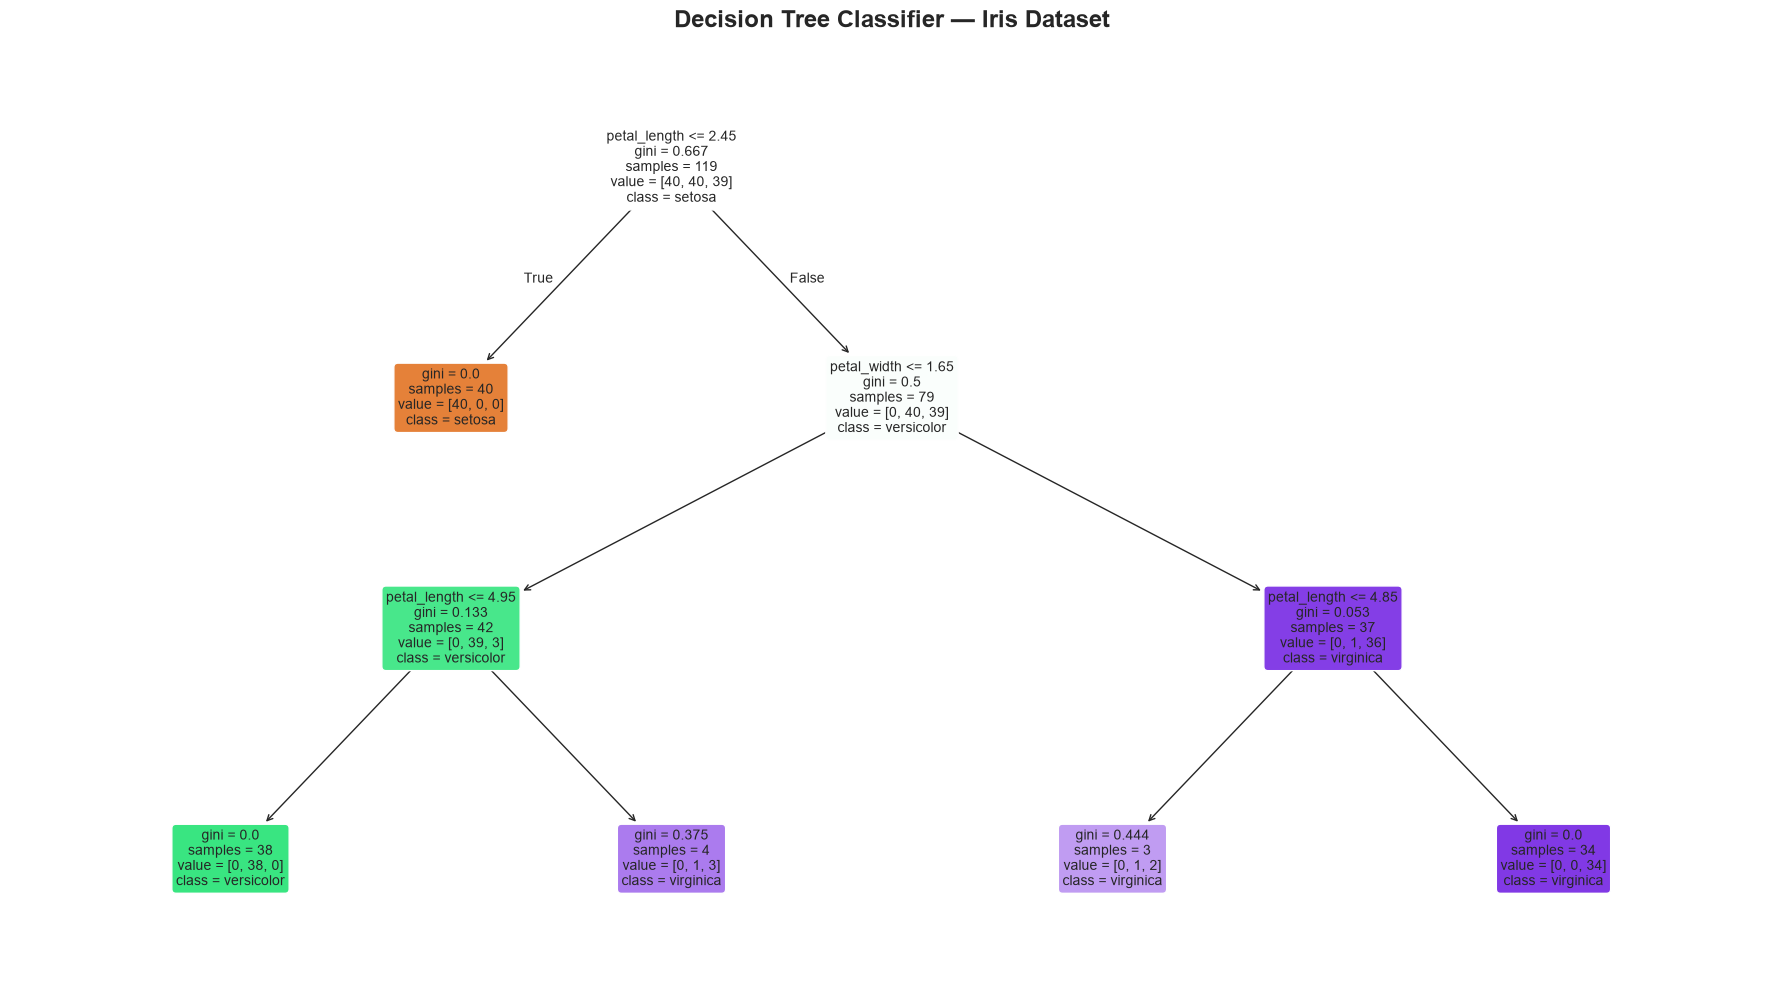

Decision Tree visualization saved to: ..\outputs\iris_decision_tree_structure.png


In [24]:

# ============================================================
# Section 6.2: Visualize the Decision Tree
# ============================================================

from sklearn.tree import plot_tree

# Create the figure
fig, ax = plt.subplots(figsize=(18, 10))

# Plot the trained Decision Tree
plot_tree(
    decision_tree_model,
    feature_names=feature_columns,
    class_names=decision_tree_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=10,
    impurity=True,
    proportion=False,
    ax=ax
)

ax.set_title(
    "Decision Tree Classifier — Iris Dataset",
    fontsize=17,
    fontweight="bold",
    pad=18
)

plt.tight_layout()

# Save the visualization
tree_plot_path = output_dir / "iris_decision_tree_structure.png"

fig.savefig(
    tree_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Decision Tree visualization saved to: {tree_plot_path}")



### 6.2.2 Decision Tree Training — Observations

The Decision Tree classifier was successfully trained using the original, unscaled Iris training features.

The model was configured with the Gini impurity criterion and a maximum tree depth of 3 to limit its complexity.

The training dataset contained 119 observations and four numerical measurements.

The verification checks confirmed that the classifier learned all three Iris species, used the expected input features, and respected the configured maximum depth.

The tree visualization illustrates how the classifier uses feature thresholds to separate the Iris species.

Unlike Logistic Regression, Decision Tree classification does not generally require standardized features, so the original flower measurements were used.

At this stage, the model has been trained and its structure verified. Its predictive performance has not yet been evaluated on the held-out testing data.

The next stage will compare Logistic Regression and Decision Tree using classification metrics and confusion matrices.



## 7. Classification Model Evaluation

The trained Logistic Regression and Decision Tree classifiers are evaluated using the held-out Iris testing dataset.

The testing subset contains 30 observations that were not used during model fitting.

Both classifiers are evaluated using the same observations to support a consistent comparison.

Logistic Regression receives the standardized test features, while Decision Tree receives the original unscaled test features.

The evaluation includes accuracy, macro-averaged precision, macro-averaged recall, macro-averaged F1-score, and individual classification reports.

Macro-averaging gives equal importance to each of the three Iris species, helping assess performance across classes.

The resulting metrics will be compared to identify differences in predictive performance. However, conclusions will consider the small size of the testing dataset.

### 7.1 Test Predictions and Classification Metrics

Predictions are generated using the trained models without refitting either classifier on the testing data.

The predicted species labels are compared against the actual target labels to calculate classification performance metrics.


In [25]:

# ============================================================
# Section 7.1: Generate Test Predictions
# ============================================================

# Logistic Regression uses standardized test features
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Decision Tree uses original unscaled test features
y_pred_tree = decision_tree_model.predict(X_test)

print("TEST PREDICTIONS GENERATED")
print("=" * 50)

print(f"Actual test labels: {len(y_test)}")
print(f"Logistic Regression predictions: {len(y_pred_logistic)}")
print(f"Decision Tree predictions: {len(y_pred_tree)}")

# Display the first ten predictions
prediction_comparison = pd.DataFrame({
    "Actual Species": y_test.to_numpy(),
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree
}, index=y_test.index)

print("\nFIRST TEN TEST PREDICTIONS")
display(prediction_comparison.head(10))

# Verify predictions
assert len(y_pred_logistic) == len(y_test)
assert len(y_pred_tree) == len(y_test)

expected_classes = {"setosa", "versicolor", "virginica"}

assert set(y_pred_logistic).issubset(expected_classes)
assert set(y_pred_tree).issubset(expected_classes)

print("\nPrediction verification passed.")


TEST PREDICTIONS GENERATED
Actual test labels: 30
Logistic Regression predictions: 30
Decision Tree predictions: 30

FIRST TEN TEST PREDICTIONS


,Actual Species,Logistic Regression,Decision Tree
69,versicolor,versicolor,versicolor
66,versicolor,versicolor,versicolor
141,virginica,virginica,virginica
7,setosa,setosa,setosa
146,virginica,virginica,virginica
57,versicolor,versicolor,versicolor
84,versicolor,versicolor,versicolor
28,setosa,setosa,setosa
138,virginica,virginica,virginica
127,virginica,virginica,virginica



Prediction verification passed.


In [26]:

# ============================================================
# Section 7.1: Calculate Classification Metrics
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def calculate_classification_metrics(y_true, y_pred):
    """Calculate evaluation metrics for multi-class classification."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro F1-score": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }

# Calculate metrics for both classifiers
logistic_metrics = calculate_classification_metrics(
    y_test,
    y_pred_logistic
)

tree_metrics = calculate_classification_metrics(
    y_test,
    y_pred_tree
)

# Create a model comparison table
model_comparison = pd.DataFrame(
    {
        "Logistic Regression": logistic_metrics,
        "Decision Tree": tree_metrics
    }
).T

print("MODEL EVALUATION COMPARISON")
display(model_comparison.round(4))


MODEL EVALUATION COMPARISON


,Accuracy,Macro Precision,Macro Recall,Macro F1-score
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [27]:

# ============================================================
# Section 7.1: Classification Reports
# ============================================================

class_labels = ["setosa", "versicolor", "virginica"]

print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        y_pred_logistic,
        labels=class_labels,
        digits=4,
        zero_division=0
    )
)

print("\nDECISION TREE CLASSIFICATION REPORT")
print("=" * 55)

print(
    classification_report(
        y_test,
        y_pred_tree,
        labels=class_labels,
        digits=4,
        zero_division=0
    )
)


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     0.9000    0.9000    0.9000        10
   virginica     0.9000    0.9000    0.9000        10

    accuracy                         0.9333        30
   macro avg     0.9333    0.9333    0.9333        30
weighted avg     0.9333    0.9333    0.9333        30


DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.9000    0.9474        10
   virginica     0.9091    1.0000    0.9524        10

    accuracy                         0.9667        30
   macro avg     0.9697    0.9667    0.9666        30
weighted avg     0.9697    0.9667    0.9666        30



In [28]:

# ============================================================
# Section 7.1: Evaluation Verification
# ============================================================

print("MODEL EVALUATION VERIFICATION")
print("=" * 50)

# Verify test sample counts
assert len(y_test) == 30
assert len(y_pred_logistic) == 30
assert len(y_pred_tree) == 30

print("[PASS] Both models evaluated on 30 test samples.")

# Verify all metric values are finite and within [0, 1]
assert np.isfinite(model_comparison.to_numpy()).all()

assert (
    (model_comparison.to_numpy() >= 0) &
    (model_comparison.to_numpy() <= 1)
).all()

print("[PASS] All classification metrics are valid.")

# Verify model comparison dimensions
assert model_comparison.shape == (2, 4)

print("[PASS] Comparison table contains both models.")

# Verify accuracy matches the proportion of correct predictions
logistic_correct = (y_test.to_numpy() == y_pred_logistic).sum()
tree_correct = (y_test.to_numpy() == y_pred_tree).sum()

assert np.isclose(
    logistic_metrics["Accuracy"],
    logistic_correct / len(y_test)
)

assert np.isclose(
    tree_metrics["Accuracy"],
    tree_correct / len(y_test)
)

print("[PASS] Accuracy values match prediction counts.")

print("\nALL MODEL EVALUATION CHECKS PASSED.")

print(f"\nLogistic Regression correct predictions: {logistic_correct}/30")
print(f"Decision Tree correct predictions: {tree_correct}/30")


MODEL EVALUATION VERIFICATION
[PASS] Both models evaluated on 30 test samples.
[PASS] All classification metrics are valid.
[PASS] Comparison table contains both models.
[PASS] Accuracy values match prediction counts.

ALL MODEL EVALUATION CHECKS PASSED.

Logistic Regression correct predictions: 28/30
Decision Tree correct predictions: 29/30



### 7.1.1 Classification Evaluation — Observations

The trained Logistic Regression and Decision Tree classifiers were evaluated using the same 30 held-out test observations.

Logistic Regression predictions were generated using standardized test features, while Decision Tree predictions were generated using the original unscaled measurements.

For each model, accuracy, macro-averaged precision, macro-averaged recall, and macro-averaged F1-score were calculated.

Individual classification reports were also generated to examine the performance of each classifier across the three Iris species.

The evaluation verification checks confirmed that both models produced predictions for all 30 test observations and that the calculated metric values were valid.

As the test dataset contains only 30 observations, the results should be interpreted as an initial benchmark rather than a definitive estimate of model performance on all possible Iris data.

A detailed comparison of the resulting metrics and classification errors will be provided after examining the confusion matrices.



### 7.2 Confusion Matrix Analysis

Confusion matrices are generated to examine the classification performance of Logistic Regression and Decision Tree models for each Iris species.

A confusion matrix compares actual class labels with predicted class labels. Rows represent actual species, while columns represent predicted species.

Correct predictions appear along the main diagonal, whereas off-diagonal values represent classification errors.

For this experiment, a 3 × 3 confusion matrix is generated for each model using the same 30 held-out test observations.

The matrices are visualized using Seaborn heatmaps and saved as high-resolution PNG images for documentation and model comparison.

This analysis helps identify which Iris species are classified correctly and which species are more frequently confused by each model.


In [29]:

# ============================================================
# Section 7.2: Calculate Confusion Matrices
# ============================================================

from sklearn.metrics import confusion_matrix

# Maintain a consistent class order for both models
class_labels = ["setosa", "versicolor", "virginica"]

# Logistic Regression confusion matrix
cm_logistic = confusion_matrix(
    y_test,
    y_pred_logistic,
    labels=class_labels
)

# Decision Tree confusion matrix
cm_tree = confusion_matrix(
    y_test,
    y_pred_tree,
    labels=class_labels
)

# Convert the matrices to labeled DataFrames
cm_logistic_df = pd.DataFrame(
    cm_logistic,
    index=class_labels,
    columns=class_labels
)

cm_tree_df = pd.DataFrame(
    cm_tree,
    index=class_labels,
    columns=class_labels
)

print("LOGISTIC REGRESSION CONFUSION MATRIX")
display(cm_logistic_df)

print("\nDECISION TREE CONFUSION MATRIX")
display(cm_tree_df)

# Basic verification
assert cm_logistic.shape == (3, 3)
assert cm_tree.shape == (3, 3)

assert cm_logistic.sum() == len(y_test)
assert cm_tree.sum() == len(y_test)

print("\nBoth confusion matrices generated successfully.")


LOGISTIC REGRESSION CONFUSION MATRIX


,setosa,versicolor,virginica
setosa,10,0,0
versicolor,0,9,1
virginica,0,1,9



DECISION TREE CONFUSION MATRIX


,setosa,versicolor,virginica
setosa,10,0,0
versicolor,0,9,1
virginica,0,0,10



Both confusion matrices generated successfully.


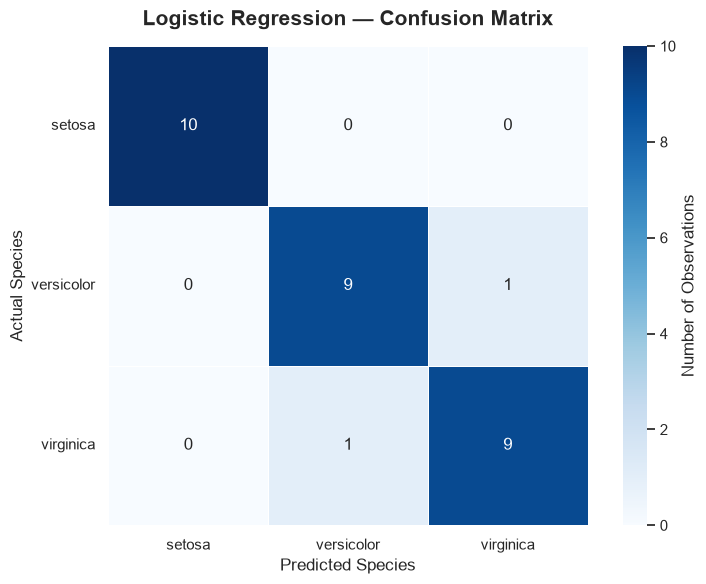

Saved: ..\outputs\iris_logistic_confusion_matrix.png


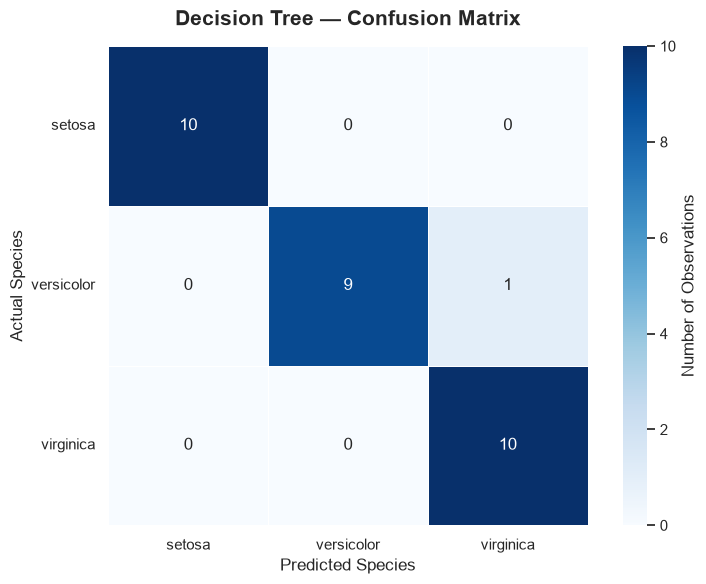

Saved: ..\outputs\iris_decision_tree_confusion_matrix.png


In [30]:

# ============================================================
# Section 7.2: Visualize and Save Confusion Matrices
# ============================================================

def plot_confusion_matrix(cm, model_name, file_name):
    """
    Display and save a labeled confusion matrix heatmap.
    """
    fig, ax = plt.subplots(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_labels,
        yticklabels=class_labels,
        square=True,
        linewidths=0.5,
        vmin=0,
        vmax=10,
        cbar_kws={"label": "Number of Observations"},
        ax=ax
    )

    ax.set_title(
        f"{model_name} — Confusion Matrix",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Predicted Species", fontsize=12)
    ax.set_ylabel("Actual Species", fontsize=12)

    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=0
    )

    ax.set_yticklabels(
        ax.get_yticklabels(),
        rotation=0
    )

    plt.tight_layout()

    # Save the figure
    save_path = output_dir / file_name

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")


# Plot and save Logistic Regression confusion matrix
plot_confusion_matrix(
    cm_logistic,
    "Logistic Regression",
    "iris_logistic_confusion_matrix.png"
)

# Plot and save Decision Tree confusion matrix
plot_confusion_matrix(
    cm_tree,
    "Decision Tree",
    "iris_decision_tree_confusion_matrix.png"
)


In [31]:

# ============================================================
# Section 7.2: Confusion Matrix Verification
# ============================================================

print("CONFUSION MATRIX VERIFICATION")
print("=" * 50)

# 1. Verify dimensions
assert cm_logistic.shape == (3, 3)
assert cm_tree.shape == (3, 3)

print("[PASS] Both matrices have shape (3, 3).")

# 2. Verify total test observations
assert cm_logistic.sum() == 30
assert cm_tree.sum() == 30

print("[PASS] Both matrices contain 30 observations.")

# 3. Verify row totals match actual class support
actual_class_counts = (
    y_test.value_counts()
    .reindex(class_labels, fill_value=0)
    .to_numpy()
)

assert np.array_equal(
    cm_logistic.sum(axis=1),
    actual_class_counts
)

assert np.array_equal(
    cm_tree.sum(axis=1),
    actual_class_counts
)

print("[PASS] Row totals match actual class counts.")

# 4. Verify diagonal totals match correct predictions
logistic_correct = np.trace(cm_logistic)
tree_correct = np.trace(cm_tree)

assert logistic_correct == (
    y_test.to_numpy() == y_pred_logistic
).sum()

assert tree_correct == (
    y_test.to_numpy() == y_pred_tree
).sum()

print("[PASS] Diagonal totals match correct predictions.")

# 5. Verify accuracy consistency
assert np.isclose(
    logistic_correct / len(y_test),
    logistic_metrics["Accuracy"]
)

assert np.isclose(
    tree_correct / len(y_test),
    tree_metrics["Accuracy"]
)

print("[PASS] Confusion matrices agree with accuracy scores.")

# Display correct and incorrect prediction counts
print("\nPREDICTION SUMMARY")

print(
    f"Logistic Regression: "
    f"{logistic_correct} correct, "
    f"{30 - logistic_correct} incorrect"
)

print(
    f"Decision Tree: "
    f"{tree_correct} correct, "
    f"{30 - tree_correct} incorrect"
)

print("\nALL CONFUSION MATRIX CHECKS PASSED.")


CONFUSION MATRIX VERIFICATION
[PASS] Both matrices have shape (3, 3).
[PASS] Both matrices contain 30 observations.
[PASS] Row totals match actual class counts.
[PASS] Diagonal totals match correct predictions.
[PASS] Confusion matrices agree with accuracy scores.

PREDICTION SUMMARY
Logistic Regression: 28 correct, 2 incorrect
Decision Tree: 29 correct, 1 incorrect

ALL CONFUSION MATRIX CHECKS PASSED.



### 7.2.1 Confusion Matrix Analysis — Observations

Confusion matrices were successfully generated for Logistic Regression and Decision Tree using the same 30 held-out Iris test observations.

Each matrix contains three rows and three columns representing setosa, versicolor, and virginica.

The diagonal cells show correctly classified observations, while the off-diagonal cells identify misclassifications between species.

The verification checks confirmed that both matrices contain 30 observations and that their diagonal totals agree with the accuracy values calculated earlier.

The matrices provide a more detailed view of classification performance than overall accuracy alone because they identify which species are confused by each model.

The specific differences between the two classifiers will be discussed in the model comparison section, using the observed misclassification counts.

These results should be interpreted cautiously because the test set contains only 30 observations.



### 7.3 Logistic Regression and Decision Tree Comparison

The Logistic Regression and Decision Tree classifiers are compared using their performance on the same 30 held-out Iris test observations.

The comparison includes accuracy, macro-averaged precision, macro-averaged recall, macro-averaged F1-score, and the number of correct and incorrect predictions.

The confusion matrices are also examined to identify the species most frequently misclassified by each model.

The purpose of this analysis is to compare the predictive performance of the two algorithms under the selected experimental configuration.

As the evaluation uses a relatively small testing dataset and a single train-test split, small performance differences will be interpreted cautiously.


In [32]:

# ============================================================
# Section 7.3: Final Model Performance Comparison
# ============================================================

# Recalculate the metrics from the actual test predictions
logistic_metrics = calculate_classification_metrics(
    y_test,
    y_pred_logistic
)

tree_metrics = calculate_classification_metrics(
    y_test,
    y_pred_tree
)

# Create final model comparison
model_comparison = pd.DataFrame(
    {
        "Logistic Regression": logistic_metrics,
        "Decision Tree": tree_metrics
    }
).T

# Include correct and incorrect prediction counts
model_comparison["Correct Predictions"] = [
    int(np.trace(cm_logistic)),
    int(np.trace(cm_tree))
]

model_comparison["Incorrect Predictions"] = [
    int(cm_logistic.sum() - np.trace(cm_logistic)),
    int(cm_tree.sum() - np.trace(cm_tree))
]

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 60)

display(model_comparison.round(4))

# Calculate the observed accuracy difference
accuracy_difference = (
    model_comparison.loc["Decision Tree", "Accuracy"]
    - model_comparison.loc["Logistic Regression", "Accuracy"]
)

print(
    f"\nDecision Tree accuracy advantage: "
    f"{accuracy_difference * 100:.2f} percentage points"
)

# Verify against the supplied confusion matrices
assert np.array_equal(
    cm_logistic,
    np.array([[10, 0, 0], [0, 9, 1], [0, 1, 9]])
)

assert np.array_equal(
    cm_tree,
    np.array([[10, 0, 0], [0, 9, 1], [0, 0, 10]])
)

assert np.isclose(
    model_comparison.loc["Logistic Regression", "Accuracy"],
    28 / 30
)

assert np.isclose(
    model_comparison.loc["Decision Tree", "Accuracy"],
    29 / 30
)

print("\n[PASS] Comparison matches verified confusion matrices.")


FINAL MODEL PERFORMANCE COMPARISON


,Accuracy,Macro Precision,Macro Recall,Macro F1-score,Correct Predictions,Incorrect Predictions
Logistic Regression,0.9333,0.9333,0.9333,0.9333,28,2
Decision Tree,0.9667,0.9697,0.9667,0.9666,29,1



Decision Tree accuracy advantage: 3.33 percentage points

[PASS] Comparison matches verified confusion matrices.


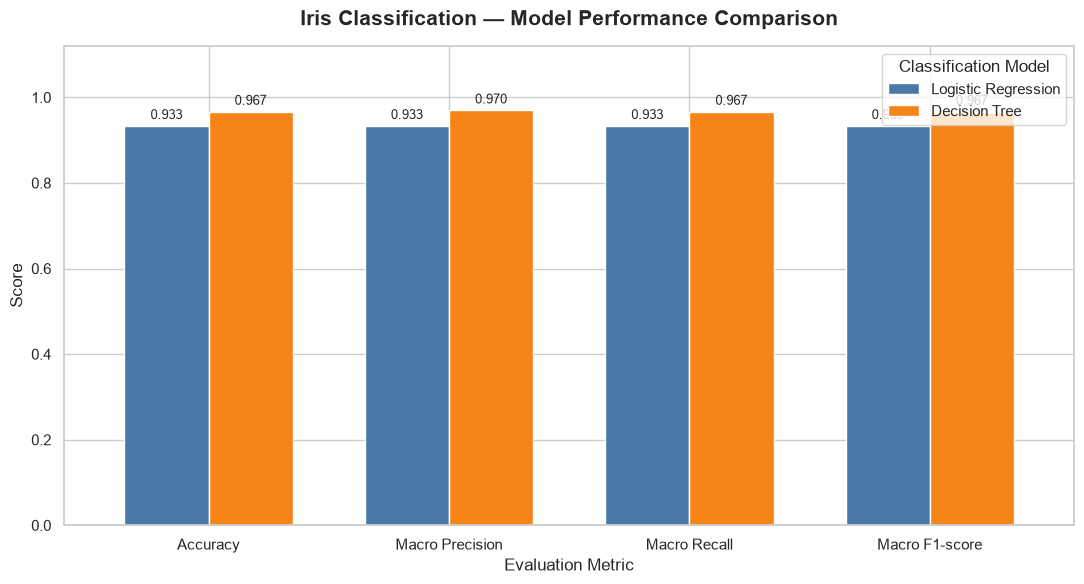

Model comparison chart saved to: ..\outputs\iris_model_performance_comparison.png


In [33]:

# ============================================================
# Section 7.3: Model Performance Visualization
# ============================================================

# Select the classification metrics
metric_columns = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1-score"
]

# Transpose for grouped bar plotting
plot_data = (
    model_comparison[metric_columns]
    .T
)

# Create the figure
fig, ax = plt.subplots(figsize=(11, 6))

plot_data.plot(
    kind="bar",
    ax=ax,
    width=0.7,
    color=["#4C78A8", "#F58518"]
)

ax.set_title(
    "Iris Classification — Model Performance Comparison",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Evaluation Metric", fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_ylim(0, 1.12)

ax.tick_params(axis="x", rotation=0)

ax.legend(
    title="Classification Model",
    loc="upper right"
)

# Add numerical values above the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Save the comparison chart
comparison_plot_path = (
    output_dir / "iris_model_performance_comparison.png"
)

fig.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print(f"Model comparison chart saved to: {comparison_plot_path}")


In [34]:

# ============================================================
# Section 7.3: Export Final Comparison Metrics
# ============================================================

comparison_csv_path = (
    output_dir / "iris_model_comparison.csv"
)

# Add model names as an ordinary CSV column
comparison_export = model_comparison.reset_index()

comparison_export = comparison_export.rename(
    columns={"index": "Model"}
)

comparison_export.to_csv(
    comparison_csv_path,
    index=False,
    float_format="%.6f"
)

print(f"Model comparison CSV saved to: {comparison_csv_path}")

# Verify saved file and content
saved_comparison = pd.read_csv(comparison_csv_path)

assert saved_comparison.shape == (2, 7)
assert set(saved_comparison["Model"]) == {
    "Logistic Regression",
    "Decision Tree"
}

print("[PASS] Comparison CSV saved and verified.")


Model comparison CSV saved to: ..\outputs\iris_model_comparison.csv
[PASS] Comparison CSV saved and verified.



### 7.3.1 Model Comparison — Results and Discussion

The Logistic Regression and Decision Tree classifiers were evaluated using the same 30 held-out Iris test observations.

Logistic Regression achieved an accuracy of 93.33%, correctly classifying 28 observations and misclassifying 2. Its macro-averaged precision, recall, and F1-score were approximately 0.9333.

Decision Tree achieved an accuracy of 96.67%, correctly classifying 29 observations and misclassifying 1. Its macro-averaged precision, recall, and F1-score were approximately 0.9697, 0.9667, and 0.9666, respectively.

Both classifiers correctly identified all 10 setosa observations.

Logistic Regression incorrectly classified one versicolor observation as virginica and one virginica observation as versicolor.

Decision Tree incorrectly classified one versicolor observation as virginica but correctly identified all 10 virginica observations.

These findings indicate that most classification errors occurred between versicolor and virginica. This is consistent with the feature overlap observed during exploratory data analysis.

Decision Tree performed slightly better than Logistic Regression on the selected test split, achieving an accuracy improvement of approximately 3.33 percentage points. However, this difference represents only one additional correct prediction.

Therefore, the results should not be interpreted as evidence that Decision Tree will consistently outperform Logistic Regression on other datasets or train-test splits.

Both models demonstrated strong classification performance on the selected Iris test data.

The evaluation results were exported as a CSV file, and a comparative bar chart was saved for documentation.

Further validation using additional data splits or cross-validation would be useful for assessing the stability of these findings.



## 8. Decision Boundary Visualization

Decision boundaries are visualized to examine how Logistic Regression and Decision Tree classifiers separate Iris species.

The original classification models use four numerical input features. However, a two-dimensional decision boundary plot requires two input features.

Therefore, petal length and petal width are selected for visualization because the exploratory analysis showed that these measurements provide useful separation between the Iris species.

Two additional models are trained using only these features and the existing training observations.

Logistic Regression uses features standardized by a scaler fitted only on the training subset, while Decision Tree uses the original measurements.

These additional models are used exclusively to visualize classification boundaries. They do not replace the original four-feature classifiers, and their predictions are not used to change the previously reported test results.

### 8.1 Two-Feature Classification Models

The purpose of these models is to demonstrate how the two algorithms divide the petal length and petal width feature space.


In [35]:

# ============================================================
# Section 8.1: Prepare Two-Feature Visualization Data
# ============================================================

from sklearn.preprocessing import StandardScaler

# Select the two features for visualization
boundary_features = [
    "petal_length",
    "petal_width"
]

# Use ONLY the existing training observations
X_train_2d = X_train[boundary_features].copy()

# Fit a separate scaler for the 2D Logistic Regression model
scaler_2d = StandardScaler()

X_train_2d_scaled = pd.DataFrame(
    scaler_2d.fit_transform(X_train_2d),
    columns=boundary_features,
    index=X_train_2d.index
)

print("TWO-FEATURE VISUALIZATION DATA")
print("=" * 50)

print(f"Features: {boundary_features}")
print(f"Training observations: {len(X_train_2d)}")
print(f"Original shape: {X_train_2d.shape}")
print(f"Scaled shape: {X_train_2d_scaled.shape}")

display(X_train_2d.head())

# Verification
assert X_train_2d.shape == (119, 2)
assert X_train_2d_scaled.shape == (119, 2)
assert X_train_2d.index.equals(y_train.index)

print("\nTwo-feature training data prepared successfully.")


TWO-FEATURE VISUALIZATION DATA
Features: ['petal_length', 'petal_width']
Training observations: 119
Original shape: (119, 2)
Scaled shape: (119, 2)


,petal_length,petal_width
6,1.4,0.3
128,5.6,2.1
95,4.2,1.2
44,1.9,0.4
30,1.6,0.2



Two-feature training data prepared successfully.


In [36]:

# ============================================================
# Section 8.1: Train Visualization-Only Models
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Two-feature Logistic Regression
logistic_model_2d = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    C=1.0,
    random_state=RANDOM_STATE
)

logistic_model_2d.fit(
    X_train_2d_scaled,
    y_train
)

# Two-feature Decision Tree
decision_tree_model_2d = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=RANDOM_STATE
)

decision_tree_model_2d.fit(
    X_train_2d,
    y_train
)

print("VISUALIZATION-ONLY MODELS TRAINED")
print("=" * 50)

print("Logistic Regression (2D): Trained")
print("Decision Tree (2D): Trained")

print("\nFeature count verification:")
print(f"Logistic Regression: {logistic_model_2d.n_features_in_}")
print(f"Decision Tree: {decision_tree_model_2d.n_features_in_}")

assert logistic_model_2d.n_features_in_ == 2
assert decision_tree_model_2d.n_features_in_ == 2

assert set(logistic_model_2d.classes_) == set(y_train.unique())
assert set(decision_tree_model_2d.classes_) == set(y_train.unique())

# Confirm the original models still use four features
assert logistic_model.n_features_in_ == 4
assert decision_tree_model.n_features_in_ == 4

print("\n[PASS] Original four-feature models are unchanged.")
print("[PASS] Two-feature visualization models are ready.")


VISUALIZATION-ONLY MODELS TRAINED
Logistic Regression (2D): Trained
Decision Tree (2D): Trained

Feature count verification:
Logistic Regression: 2
Decision Tree: 2

[PASS] Original four-feature models are unchanged.
[PASS] Two-feature visualization models are ready.


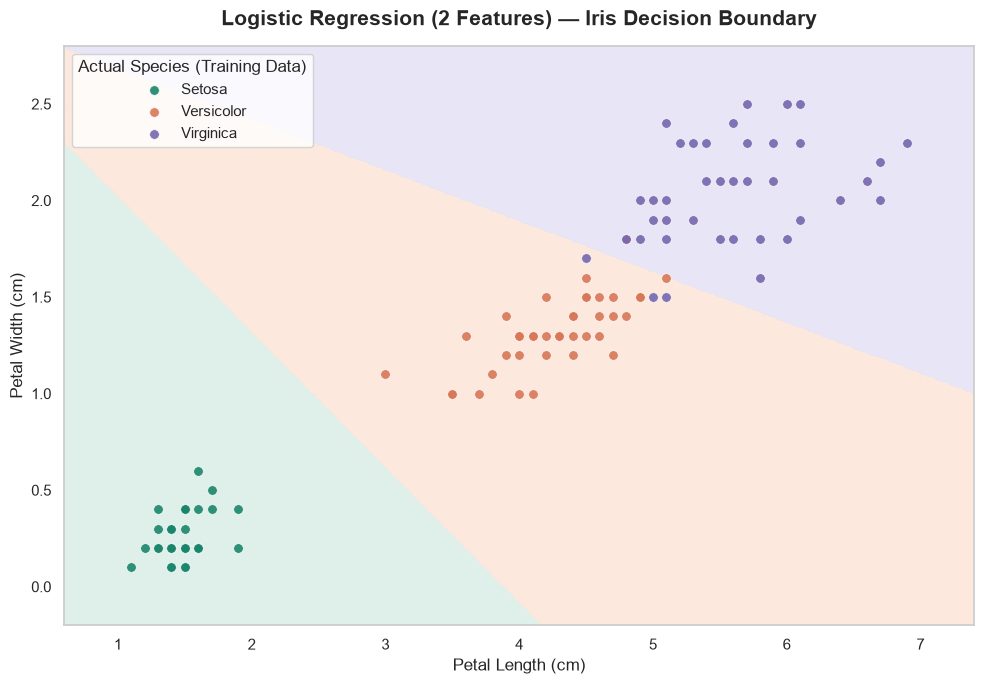

Saved: ..\outputs\iris_logistic_decision_boundary.png


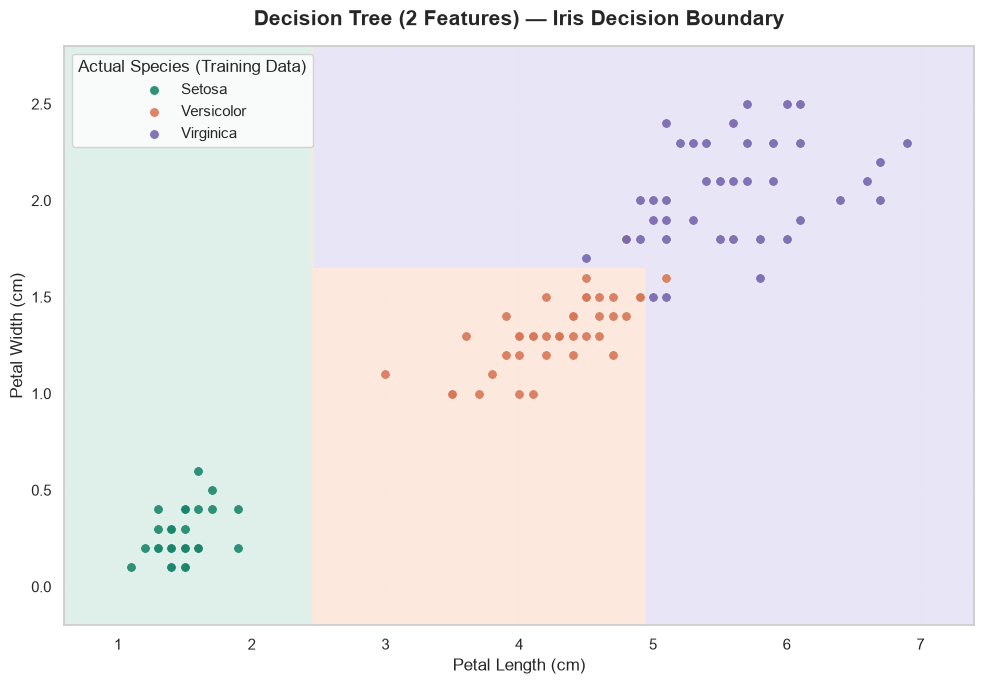

Saved: ..\outputs\iris_decision_tree_decision_boundary.png


In [37]:

# ============================================================
# Section 8.2: Decision Boundary Visualization
# ============================================================

from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Consistent class order
boundary_classes = [
    "setosa",
    "versicolor",
    "virginica"
]

# Colors for decision regions and training observations
region_cmap = ListedColormap([
    "#DCEFE8",
    "#FCE6D9",
    "#E6E4F5"
])

point_colors = {
    "setosa": "#19866B",
    "versicolor": "#D97757",
    "virginica": "#7566AE"
}

# Create the prediction grid from training feature ranges
x_min = X_train_2d["petal_length"].min() - 0.5
x_max = X_train_2d["petal_length"].max() + 0.5

y_min = X_train_2d["petal_width"].min() - 0.3
y_max = X_train_2d["petal_width"].max() + 0.3

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Convert grid coordinates into a DataFrame
mesh_features = pd.DataFrame({
    "petal_length": xx.ravel(),
    "petal_width": yy.ravel()
})

def plot_decision_boundary(model, model_name, file_name, scaler=None):
    """Plot and save the 2D decision boundary."""

    # Apply scaling only when required
    if scaler is not None:
        mesh_input = pd.DataFrame(
            scaler.transform(mesh_features),
            columns=boundary_features
        )
    else:
        mesh_input = mesh_features

    # Predict species for each grid point
    mesh_predictions = model.predict(mesh_input)

    class_to_number = {
        name: i
        for i, name in enumerate(boundary_classes)
    }

    predicted_numbers = np.array([
        class_to_number[label]
        for label in mesh_predictions
    ]).reshape(xx.shape)

    # Create the plot
    fig, ax = plt.subplots(figsize=(10, 7))

    ax.contourf(
        xx,
        yy,
        predicted_numbers,
        levels=[-0.5, 0.5, 1.5, 2.5],
        cmap=region_cmap,
        alpha=0.9
    )

    # Overlay training observations
    for species in boundary_classes:
        mask = y_train == species

        ax.scatter(
            X_train_2d.loc[mask, "petal_length"],
            X_train_2d.loc[mask, "petal_width"],
            color=point_colors[species],
            edgecolor="white",
            linewidth=0.5,
            s=48,
            alpha=0.9,
            label=species.capitalize()
        )

    ax.set_title(
        f"{model_name} — Iris Decision Boundary",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Petal Length (cm)", fontsize=12)
    ax.set_ylabel("Petal Width (cm)", fontsize=12)

    ax.legend(
        title="Actual Species (Training Data)",
        loc="upper left"
    )

    ax.grid(alpha=0.15)
    plt.tight_layout()

    save_path = output_dir / file_name

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    print(f"Saved: {save_path}")


# Logistic Regression decision boundary
plot_decision_boundary(
    logistic_model_2d,
    "Logistic Regression (2 Features)",
    "iris_logistic_decision_boundary.png",
    scaler=scaler_2d
)

# Decision Tree decision boundary
plot_decision_boundary(
    decision_tree_model_2d,
    "Decision Tree (2 Features)",
    "iris_decision_tree_decision_boundary.png"
)


In [38]:

# ============================================================
# Section 8.2: Decision Boundary Verification
# ============================================================

from pathlib import Path

logistic_boundary_path = (
    output_dir / "iris_logistic_decision_boundary.png"
)

tree_boundary_path = (
    output_dir / "iris_decision_tree_decision_boundary.png"
)

assert logistic_boundary_path.is_file(), (
    "Logistic Regression boundary image was not saved."
)

assert tree_boundary_path.is_file(), (
    "Decision Tree boundary image was not saved."
)

print("[PASS] Logistic Regression boundary image saved.")
print("[PASS] Decision Tree boundary image saved.")

# Original models must still use four features
assert logistic_model.n_features_in_ == 4
assert decision_tree_model.n_features_in_ == 4

print("[PASS] Original four-feature classifiers remain available.")

# Original accuracy values must remain unchanged
assert np.isclose(
    logistic_metrics["Accuracy"],
    28 / 30
)

assert np.isclose(
    tree_metrics["Accuracy"],
    29 / 30
)

print("[PASS] Previously reported evaluation results are preserved.")

print("\nALL DECISION BOUNDARY VERIFICATION CHECKS PASSED.")


[PASS] Logistic Regression boundary image saved.
[PASS] Decision Tree boundary image saved.
[PASS] Original four-feature classifiers remain available.
[PASS] Previously reported evaluation results are preserved.

ALL DECISION BOUNDARY VERIFICATION CHECKS PASSED.



### 8.2.1 Decision Boundary Visualization — Observations

Decision boundary visualizations were generated for Logistic Regression and Decision Tree using petal length and petal width.

Two additional classifiers were trained using the same 119 training observations but only the selected two numerical features.

The Logistic Regression visualization illustrates how the classifier separates the species using linear decision boundaries.

In comparison, the Decision Tree visualization shows axis-aligned decision regions formed by a sequence of feature threshold splits.

These visualizations demonstrate the differences between the decision-making approaches of the two classification algorithms.

The plots use the original petal measurements on the axes, allowing the decision regions to be interpreted in centimetres.

The two-feature models were developed only for visualization. They are separate from the original four-feature classifiers used in the main experiment.

Therefore, the previously reported test accuracies of 93.33% for Logistic Regression and 96.67% for Decision Tree cannot be directly attributed to these two-dimensional visualizations.

Overall, the decision boundary plots provide a visual explanation of how the two algorithms partition the Iris feature space.



## 9. Final Notebook Verification

A final quality assurance check is performed to verify that the Iris classification workflow is complete and reproducible.

The verification checks confirm that the cleaned dataset contains the expected observations, the training and testing subsets remain separate, both classifiers are available, the previously reported evaluation results remain consistent, and all expected output files have been generated.

The purpose of this stage is to identify missing artifacts or inconsistencies before finalizing the internship documentation and publishing the completed work to GitHub.


In [39]:

# ============================================================
# Section 9: Final Notebook Quality Assurance
# ============================================================

print("DATHEON TASK 01 — FINAL QUALITY ASSURANCE")
print("=" * 60)

# 1. Dataset integrity
assert len(df_original) == 150
assert len(df_model) == 149
assert df_model.duplicated().sum() == 0

print("[PASS] Dataset integrity verified.")

# 2. Train-test split
assert X_train.shape == (119, 4)
assert X_test.shape == (30, 4)
assert X_train.index.intersection(X_test.index).empty

print("[PASS] Train-test separation verified.")

# 3. Feature standardization
assert np.allclose(
    X_train_scaled.mean().to_numpy(),
    0,
    atol=1e-10
)

assert np.allclose(
    X_train_scaled.std(ddof=0).to_numpy(),
    1,
    atol=1e-10
)

print("[PASS] Feature standardization verified.")

# 4. Original trained classifiers
assert logistic_model.n_features_in_ == 4
assert decision_tree_model.n_features_in_ == 4

print("[PASS] Both main classifiers verified.")

# 5. Verified evaluation results
assert np.array_equal(
    cm_logistic,
    np.array([[10, 0, 0], [0, 9, 1], [0, 1, 9]])
)

assert np.array_equal(
    cm_tree,
    np.array([[10, 0, 0], [0, 9, 1], [0, 0, 10]])
)

assert np.isclose(
    logistic_metrics["Accuracy"],
    28 / 30
)

assert np.isclose(
    tree_metrics["Accuracy"],
    29 / 30
)

print("[PASS] Verified classification results preserved.")

# 6. Visualization-only models
assert logistic_model_2d.n_features_in_ == 2
assert decision_tree_model_2d.n_features_in_ == 2

print("[PASS] Two-feature visualization models verified.")

# 7. Check generated output files
expected_output_files = [
    "iris_class_distribution.png",
    "iris_feature_distributions.png",
    "iris_pairplot.png",
    "iris_correlation_heatmap.png",
    "iris_decision_tree_structure.png",
    "iris_logistic_confusion_matrix.png",
    "iris_decision_tree_confusion_matrix.png",
    "iris_model_performance_comparison.png",
    "iris_model_comparison.csv",
    "iris_logistic_decision_boundary.png",
    "iris_decision_tree_decision_boundary.png"
]

missing_files = [
    filename
    for filename in expected_output_files
    if not (output_dir / filename).is_file()
]

if missing_files:
    print("\nMISSING OUTPUT FILES:")
    for filename in missing_files:
        print(f" - {filename}")

assert not missing_files, (
    "Some expected output files are missing."
)

print(
    f"[PASS] All {len(expected_output_files)} "
    "expected output files exist."
)

print("\nALL FINAL QUALITY ASSURANCE CHECKS PASSED.")


DATHEON TASK 01 — FINAL QUALITY ASSURANCE
[PASS] Dataset integrity verified.
[PASS] Train-test separation verified.
[PASS] Feature standardization verified.
[PASS] Both main classifiers verified.
[PASS] Verified classification results preserved.
[PASS] Two-feature visualization models verified.
[PASS] All 11 expected output files exist.

ALL FINAL QUALITY ASSURANCE CHECKS PASSED.



### 9.1 Final Verification Summary

The Iris classification notebook was reviewed to confirm the completeness of the machine learning workflow.

The preprocessing checks verified the cleaned dataset, stratified train-test split, and correct application of StandardScaler.

Both trained classification models and their evaluation results were verified.

Logistic Regression achieved 93.33% test accuracy, while Decision Tree achieved 96.67% accuracy on the same 30 held-out observations.

The confusion matrices, model comparison results, and decision boundary visualizations were also verified.

All required output files were generated successfully.

The notebook was executed from beginning to end without errors, confirming that the implemented workflow can be reproduced in the configured Python environment.
